In [1]:
import io
import sys
from collections import Counter
from contextlib import redirect_stdout
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from imblearn.over_sampling import ADASYN, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import (
    SelectFromModel,
    SequentialFeatureSelector,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    log_loss,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
)
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline  # Pipeline estándar
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    StandardScaler,
)

# Enrutamiento de metadatos: lleva `groups` hasta el CV interno
# del selector de variables
sklearn.set_config(enable_metadata_routing=True)

sys.path.insert(0, str(Path.cwd().parent))

from config import config
from utils.evaluador_cv import EvaluadorCV


def cox_snell_r2(model, X, y):
    """
    Calcula el R² de Cox & Snell para Regresión Logística.
    Requires probabilidades predichas del modelo.
    """
    n = len(y)
    # Log-likelihood del modelo actual
    probs = model.predict_proba(X)
    ll_model = -log_loss(y, probs, normalize=False)

    # Log-likelihood del modelo nulo (solo intercepto)
    p_null = np.mean(y)
    ll_null = np.sum(y * np.log(p_null) + (1 - y) * np.log(1 - p_null))

    return 1 - np.exp((2 / n) * (ll_null - ll_model))


def nagelkerke_r2(model, X, y):
    """
    Calcula el R² de Nagelkerke ajustando la escala entre 0 y 1.
    """
    n = len(y)
    p_null = np.mean(y)
    ll_null = np.sum(y * np.log(p_null) + (1 - y) * np.log(1 - p_null))

    cs_r2 = cox_snell_r2(model, X, y)
    max_r2 = 1 - np.exp((2 / n) * ll_null)

    return cs_r2 / max_r2


DIR_SPLITS = config.DATADIR / "splits"

# test.pkl no se abre hasta la evaluación final del proyecto
df_train = pd.read_pickle(DIR_SPLITS / "train.pkl")
df_val = pd.read_pickle(DIR_SPLITS / "val.pkl")
assert list(df_train.columns) == list(df_val.columns)

# Papel de cada columna (ver la conclusión de eda_consolidate.ipynb)
LLAVES = ["DIRECTORIO", "SECUENCIA_P"]  # trazabilidad, nunca entran a X
GRUPO = "SEGMENTO"  # grupos para StratifiedGroupKFold
PESO = "PESO"  # solo si se pondera el modelo
OBJETIVO = "POBRE"
CARACTERISTICAS = [
    c for c in df_train.columns if c not in [*LLAVES, GRUPO, PESO, OBJETIVO]
]

RANDOM_STATE = 42

# Cargar datos

In [2]:
X_train, y_train = df_train[CARACTERISTICAS], df_train[OBJETIVO]
grupos_train = df_train[GRUPO]
X_val, y_val = df_val[CARACTERISTICAS], df_val[OBJETIVO]

pd.DataFrame(
    {
        "hogares": [len(df_train), len(df_val)],
        "tasa POBRE": [y_train.mean(), y_val.mean()],
    },
    index=["train", "val"],
)

,hogares,tasa POBRE
train,31039,0.128419
val,6643,0.128707


# Generar funciones de evaluación custom

In [3]:
UMBRAL = 0.5  # umbral de decisión para las métricas que lo necesitan


def custom_accuracy(y_true, y_proba, threshold):
    return accuracy_score(y_true, y_proba >= threshold)


def custom_precision(y_true, y_proba, threshold):
    return precision_score(y_true, y_proba >= threshold, zero_division=0)


def custom_recall(y_true, y_proba, threshold):
    return recall_score(y_true, y_proba >= threshold, zero_division=0)


def custom_kappa(y_true, y_proba, threshold):
    return cohen_kappa_score(y_true, y_proba >= threshold)


def crear_scoring(umbral):
    """Scorers con el umbral explícito.

    Para evaluar con otro umbral basta con volver a llamar la función:
    el umbral no queda congelado al definir las funciones.
    """

    def con_umbral(funcion):
        return make_scorer(
            funcion, response_method="predict_proba", threshold=umbral
        )

    return {
        "accuracy": con_umbral(custom_accuracy),
        "precision": con_umbral(custom_precision),
        "recall": con_umbral(custom_recall),
        "kappa": con_umbral(custom_kappa),
        # No depende del umbral: AP evalúa todos los umbrales
        "average_precision": "average_precision",
    }

# Modelo línea base

Se utiliza como línea base un predictor trivial de la moda, esto se utilizará como punto de partida para establecer qué es lo que deben mejorar los modelos posteriores.


In [4]:
dummy_clas = DummyClassifier(strategy="most_frequent")

dummy_model_pipeline = Pipeline([("model", dummy_clas)])

sgkf = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

scores = cross_validate(
    estimator=dummy_model_pipeline,
    X=X_train,
    y=y_train,
    params={"groups": grupos_train},
    cv=sgkf,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "average_precision",
    ],  # average_precision es una aproximacion de PR-AUC
)

/Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/.venv/lib/python3.14/site-packages/sklearn

In [5]:
for metric, val in scores.items():
    print(f"{metric}: {val.mean()}")

fit_time: 0.0025825977325439455
score_time: 0.0036633968353271484
test_accuracy: 0.8715804473532263
test_precision: 0.0
test_recall: 0.0
test_average_precision: 0.12841955264677368


Matriz de confusión:
 [[27053     0]
 [ 3986     0]]


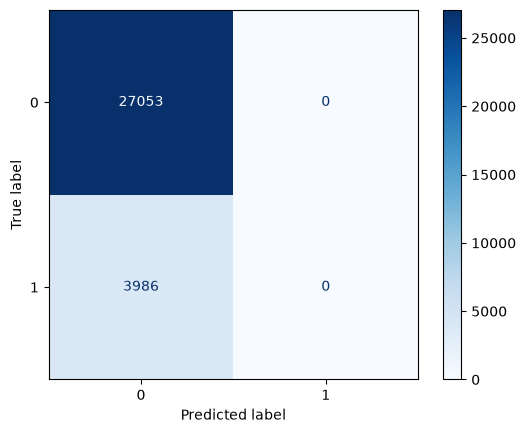

In [6]:
y_pred_dummy = cross_val_predict(
    estimator=dummy_model_pipeline,
    X=X_train,
    y=y_train,
    params={"groups": grupos_train},
    cv=sgkf,
)

# 2. Generar la matriz en texto/array
cm = confusion_matrix(y_train, y_pred_dummy)
print("Matriz de confusión:\n", cm)

# 3. Graficar la matriz de forma visual
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")

Note que el modelo dummy da un accuracy promedio entre folds realmente alto (0.87), sin embargo esto es un artefacto del desbalance de clases, pues su recall es 0 y su precisión da error matemático pero la librería la vuelve 0, dicho esto lo que deberá buscar en modelos posteriores es obtener un mayor recall ya que es más crítico detectar personas pobres, esto con el fin de evitar la omisión de personas vulnerables, esto sin sacrificar en gran medida la precisión para no clasificar mal sistematicamente. Esto se puede lograr sacrificando ese accuracy tan alto y se puede controlar su equilibrio utilizando la curva PR y PR-AUC o `average_precision` (no la ROC ya que el problema es desbalanceado).

# Primera propuesta de pipeline: Regresión Logística usando pesos para lidiar con el desbalance

A continuación se presenta la primera propuesta de modelación, una regresión logística, donde el primer paso consta de imputar los faltantes con el método propuesto en el cuaderno anterior, para posteriormente seleccionar 6 variables usando un método de selección secuencial y por último entrenar la regresión utilizando una función de coste pesada (rebalanceo por pesos).

Se omiten pasos como el escalamiento ya que las variables o son proporciones entre 0 y 1 o ya son variables codificadas según el contexto, como se reporto en el notebook anterior (una de hecho ya venía codificada en la base original del DANE). 

El equipo considera útil justificar la razón de que la primera propuesta utilice por método de balanceo el peso por clases, ya que no era muy usual en modelos anteriores del curso (especialmente en KNN), no obstante en un modelo como regresión lineal suele ser extremadamente útil, pues los pesos funcionan como una suerte de "engaño" a la función de coste que eventualmente hace que el gradiente converja a un punto donde el modelo aprendió a minimizar el error con la minoría (pues a esta se le establece un mayor coste), de ahí que los pesos sean utiles en modelos ajustados mediante la optimización de alguna función de coste, por lo tanto la estructura de la pipeline es así:

- Imputación
- Selección de 6 características
- Regresión Logística Ponderada

## Crear Pipeline

In [7]:
model_log_reg_1 = LogisticRegression(class_weight="balanced", max_iter=1000)

cv_interno = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=RANDOM_STATE + 1
)

weighted_log_reg = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=model_log_reg_1,
                n_features_to_select=6,
                direction="backward",
                scoring="average_precision",  # Evalúa la selección con PR-AUC
                cv=cv_interno,
                n_jobs=-1,  # Acelera la selección en paralelo
            ),
        ),
        ("model", model_log_reg_1),
    ]
)

## Evaluar con CV

In [8]:
print(f"umbral: {UMBRAL}")
scores = cross_validate(
    estimator=weighted_log_reg,
    X=X_train,
    y=y_train,
    params={"groups": grupos_train},
    cv=sgkf,
    scoring=crear_scoring(UMBRAL),
    return_estimator=True,
    return_indices=True,
)

umbral: 0.5


In [9]:
for metric, val in scores.items():
    # 'estimator' e 'indices' no son métricas
    if metric not in ("estimator", "indices"):
        print(f"{metric}: {np.mean(val):.3f} ± {np.std(val):.3f}")

fit_time: 5.961 ± 2.099
score_time: 0.007 ± 0.000
test_accuracy: 0.763 ± 0.004
test_precision: 0.245 ± 0.008
test_recall: 0.407 ± 0.018
test_kappa: 0.173 ± 0.012
test_average_precision: 0.257 ± 0.012


In [10]:
registros = []
n_folds = len(scores["estimator"])

for idx, pipeline in enumerate(scores["estimator"]):
    imputer = pipeline.named_steps["imputer"]
    selector = pipeline.named_steps["select_vars"]
    modelo = pipeline.named_steps["model"]

    # 1. Recuperar los nombres de las columnas que genera el SimpleImputer
    # (Incluye las variables originales y las columnas indicadoras si hubo
    # nulos)
    nombres_imputed = imputer.get_feature_names_out(X_train.columns)

    # 2. Filtrar las 6 columnas seleccionadas por el SequentialFeatureSelector
    nombres_seleccionados = nombres_imputed[selector.get_support()]

    # 3. Guardar variables y coeficientes de este fold
    for var, coef in zip(nombres_seleccionados, modelo.coef_[0]):
        registros.append(
            {"fold": idx, "Característica": var, "Coeficiente": coef}
        )

df_coefs_todos = pd.DataFrame(registros)

# 4. Agrupar para ver promedio, desviación estándar y en cuántos folds fue
# seleccionada cada variable
df_resumen_coef = (
    df_coefs_todos.groupby("Característica")["Coeficiente"]
    .agg(
        Coef_Promedio="mean",
        Coef_Std="std",
        Veces_Seleccionada="count",
    )
    .sort_values(by="Veces_Seleccionada", ascending=False)
)

df_resumen_coef["Porcentaje"] = (
    df_resumen_coef["Veces_Seleccionada"] / n_folds
) * 100

display(df_resumen_coef)

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje
Característica,,,,
ORG_alcantarillado,0.476506,0.125398,5,100.0
ORG_analfabetismo,2.676788,0.052811,5,100.0
ORG_fuente_agua_cocinar,0.025820,0.004382,5,100.0
ORG_trabajo_infantil,1.007562,0.100860,5,100.0
missingindicator_ORG_trabajo_infantil,-0.257345,0.011416,5,100.0
ORG_servicio_sanitario,0.121500,0.014758,3,60.0
ORG_sin_aseguramiento,-0.030504,0.035079,2,40.0


In [11]:
feature_counts = Counter()

for estimator in scores["estimator"]:
    # Nombres de variables después del imputer
    feat_names = estimator.named_steps["imputer"].get_feature_names_out(
        X_train.columns
    )

    # Máscara de las variables seleccionadas en este fold
    mask = estimator.named_steps["select_vars"].get_support()

    # Acumular las variables seleccionadas
    selected_in_fold = feat_names[mask]
    feature_counts.update(selected_in_fold)

# 2. Convertir a DataFrame para presentar los resultados organizados
n_folds = len(scores["estimator"])
df_frequencies = (
    pd.DataFrame(feature_counts.items(), columns=["Variable", "Frecuencia"])
    .sort_values(by="Frecuencia", ascending=False)
    .reset_index(drop=True)
)

# Agregar la proporción/porcentaje de selección
df_frequencies["Porcentaje"] = (df_frequencies["Frecuencia"] / n_folds) * 100

print(f"--- Frecuencia de selección de variables ({n_folds} Folds) ---")
print(df_frequencies.to_string(index=False))

--- Frecuencia de selección de variables (5 Folds) ---
                             Variable  Frecuencia  Porcentaje
                    ORG_analfabetismo           5       100.0
                 ORG_trabajo_infantil           5       100.0
              ORG_fuente_agua_cocinar           5       100.0
                   ORG_alcantarillado           5       100.0
missingindicator_ORG_trabajo_infantil           5       100.0
               ORG_servicio_sanitario           3        60.0
                ORG_sin_aseguramiento           2        40.0


In [12]:
# Probabilidades de cada pliegue con los modelos que ya ajustó
# cross_validate: no se reentrena nada
probas_cv = [
    (
        y_train.iloc[idx_te],
        estimador.predict_proba(X_train.iloc[idx_te])[:, 1],
    )
    for estimador, idx_te in zip(
        scores["estimator"], scores["indices"]["test"]
    )
]

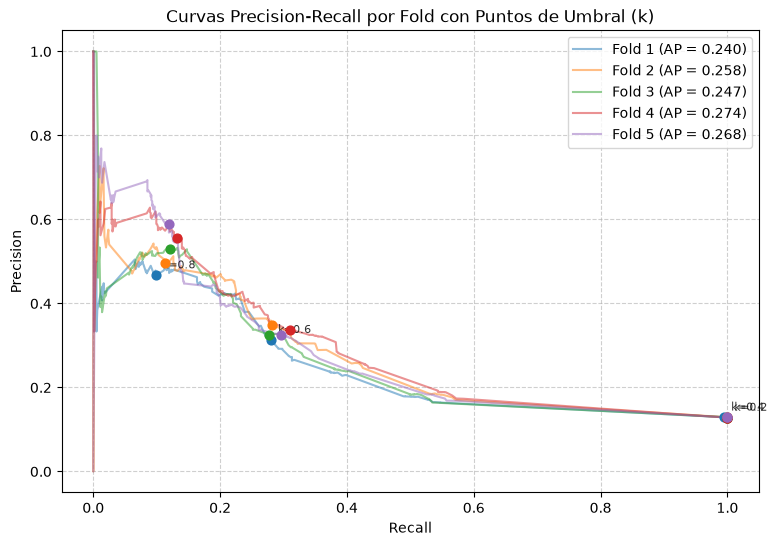

In [13]:
# Umbrales k (puntos de corte) que quieres visualizar en las curvas
thresholds_to_show = [0.2, 0.4, 0.6, 0.8]

fig, ax = plt.subplots(figsize=(9, 6))

# Probabilidades ya calculadas por pliegue (sin reentrenar)
for fold, (y_te, y_proba) in enumerate(probas_cv):
    # 1. Calcular precisión, recall y umbrales (thresholds)
    precision, recall, thresholds = precision_recall_curve(y_te, y_proba)
    ap = average_precision_score(y_te, y_proba)

    # 2. Graficar la curva PR del fold
    (line,) = ax.plot(
        recall, precision, alpha=0.5, label=f"Fold {fold + 1} (AP = {ap:.3f})"
    )
    fold_color = line.get_color()

    # 3. Marcar los umbrales k en la curva
    for k in thresholds_to_show:
        # Encontrar el índice del umbral más cercano a k
        idx = np.argmin(np.abs(thresholds - k))
        r_k, p_k = recall[idx], precision[idx]

        # Dibujar punto sobre la curva
        ax.scatter(r_k, p_k, color=fold_color, s=40, zorder=5)

        # Etiquetar el valor de k (solo en el Fold 1, para no saturar)
        if fold == 0:
            ax.annotate(
                f"k={k}",
                (r_k, p_k),
                textcoords="offset points",
                xytext=(5, 5),
                fontsize=8,
                alpha=0.8,
            )

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Curvas Precision-Recall por Fold con Puntos de Umbral (k)")
ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()

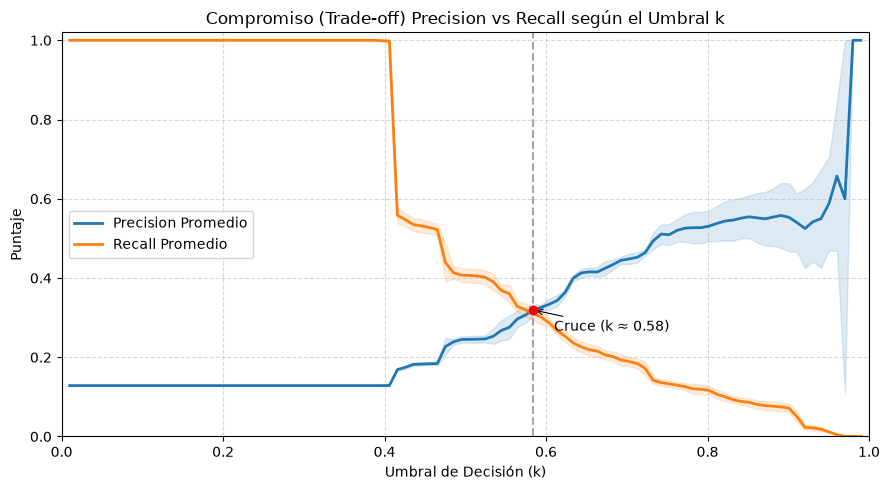

In [14]:
# 1. Definir una malla de umbrales k desde 0 hasta 1
k_thresholds = np.linspace(0.01, 0.99, 100)

# Listas para almacenar las métricas por fold
precisions_per_k = []
recalls_per_k = []

# 2. Iterar sobre las probabilidades de cada fold (sin reentrenar)
for y_te, y_proba in probas_cv:
    # Evaluar Precision y Recall para cada k en la malla
    fold_precisions = []
    fold_recalls = []

    for k in k_thresholds:
        y_pred_k = (y_proba >= k).astype(int)

        # Calcular métricas para el umbral k
        tp = np.sum((y_te == 1) & (y_pred_k == 1))
        fp = np.sum((y_te == 0) & (y_pred_k == 1))
        fn = np.sum((y_te == 1) & (y_pred_k == 0))

        prec = tp / (tp + fp) if (tp + fp) > 0 else 1.0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0

        fold_precisions.append(prec)
        fold_recalls.append(rec)

    precisions_per_k.append(fold_precisions)
    recalls_per_k.append(fold_recalls)

# 3. Promediar el comportamiento a través de los folds
mean_precision = np.mean(precisions_per_k, axis=0)
std_precision = np.std(precisions_per_k, axis=0)

mean_recall = np.mean(recalls_per_k, axis=0)
std_recall = np.std(recalls_per_k, axis=0)

# 4. Graficar Precision y Recall vs Umbral k
fig, ax = plt.subplots(figsize=(9, 5))

# Curva de Precision
ax.plot(
    k_thresholds,
    mean_precision,
    label="Precision Promedio",
    color="#1f77b4",
    lw=2,
)
ax.fill_between(
    k_thresholds,
    np.clip(mean_precision - std_precision, 0, 1),
    np.clip(mean_precision + std_precision, 0, 1),
    color="#1f77b4",
    alpha=0.15,
)

# Curva de Recall
ax.plot(
    k_thresholds, mean_recall, label="Recall Promedio", color="#ff7f0e", lw=2
)
ax.fill_between(
    k_thresholds,
    np.clip(mean_recall - std_recall, 0, 1),
    np.clip(mean_recall + std_recall, 0, 1),
    color="#ff7f0e",
    alpha=0.15,
)

# Marcar el punto donde se intersectan (Trade-off equilibrado)
idx_intersection = np.argmin(np.abs(mean_precision - mean_recall))
k_intersect = k_thresholds[idx_intersection]
val_intersect = mean_precision[idx_intersection]

ax.axvline(x=k_intersect, color="grey", linestyle="--", alpha=0.7)
ax.scatter([k_intersect], [val_intersect], color="red", zorder=5)
ax.annotate(
    f"Cruce (k ≈ {k_intersect:.2f})",
    (k_intersect, val_intersect),
    xytext=(15, -15),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="black", lw=0.8),
)

ax.set_xlabel("Umbral de Decisión (k)")
ax.set_ylabel("Puntaje")
ax.set_title("Compromiso (Trade-off) Precision vs Recall según el Umbral k")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [15]:
ev = EvaluadorCV(
    weighted_log_reg, X_train, y_train, 0.45, grupos_train, pickle=True
)

In [16]:
ev.evaluar_cv()

umbral: 0.45
Resultados cargados de caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/2015d691925edf5ac233fbe801ce6661.pkl


In [17]:
ev.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_alcantarillado,0.476506,0.125398,5,100.0,1.610437,1.431096,1.869349
ORG_analfabetismo,2.676788,0.052811,5,100.0,14.538314,13.311411,15.114109
ORG_fuente_agua_cocinar,0.025820,0.004382,5,100.0,1.026156,1.019178,1.030708
ORG_trabajo_infantil,1.007562,0.100860,5,100.0,2.738916,2.466966,3.178163
missingindicator_ORG_trabajo_infantil,-0.257345,0.011416,5,100.0,0.773101,0.766036,0.787811
ORG_servicio_sanitario,0.121500,0.014758,3,60.0,1.129190,1.111101,1.143721
ORG_sin_aseguramiento,-0.030504,0.035079,2,40.0,0.969957,0.946193,0.994317


Matriz de confusión:
 [[17646  9407]
 [ 1873  2113]]


<Axes: xlabel='Predicted label', ylabel='True label'>

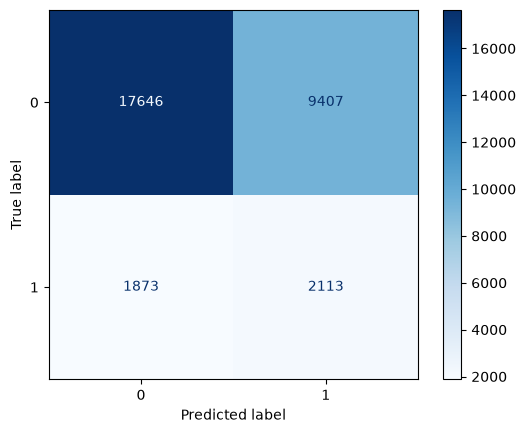

In [18]:
ev.matriz_confusion()

In [19]:
ev.resumen_metricas()

fit_time: 4.962 ± 0.796
score_time: 0.007 ± 0.001
test_accuracy: 0.637 ± 0.003
test_precision: 0.183 ± 0.004
test_recall: 0.530 ± 0.016
test_kappa: 0.101 ± 0.007
test_average_precision: 0.257 ± 0.012


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

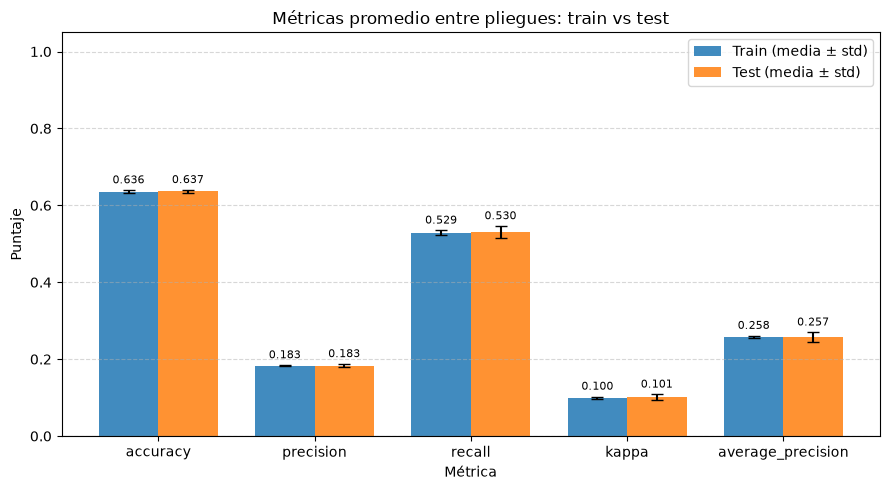

In [20]:
ev.comparar_train_test()

In [21]:
ev.pseudo_r2()

Cox_Snell: -0.688 ± 0.006
Nagelkerke: -1.284 ± 0.012


,Cox_Snell,Nagelkerke
fold,,
0,-0.694181,-1.297752
1,-0.685910,-1.277988
2,-0.686479,-1.283071
3,-0.693852,-1.296958
4,-0.678605,-1.266663


- Los Pseudo-$R^2$ son métricas diseñadas bajo el supuesto de máxima verosimilitud sin modificar las prioris ($class\_weight$).

- El valor negativo no indica que el modelo no funcione o no sepa ordenar, sino que sus probabilidades no están calibradas con la prevalencia real.

- Por esta razón, para problemas con desbalance y pesos ajustados, el Average Precision (AP / PR-AUC) o la curva ROC-AUC son métricas infinitamente más fiables que el Pseudo-$R^2$.

## Interpretar resultados

Este modelo tiene un accuracy menor que el de la línea base, no obstante mejora abismalmente la detección de la clase positiva (pobre), no obstante no es del todo satisfactorio, ya que independientemente del umbral no se logra tener un recall considerable a costa de una precisión muy deficiente (si bien existe el típico trade-off entre esas 2 métricas se busca que no sea tan intenso), consulte también el gráfico de la curva pr donde para cualquier umbral la curva está lejos y por un amplio margen del ideal, adicionalmente su kappa indica que no es mejor que el azar por un margen especialmente alto.

Adicionalmente el modelo ajustado considera como el factor que más aumenta la probabilidad de ser pobre el ORG_analfabetismo (proporción de personas analfabetas en el hogar), pues se le asigna un $\text{AOR} \approx 14.57$.

Después de lo expuesto se considera que este modelo no fue satisfactorio y se plantean más iteraciones con el fin de buscar un mejor modelado (Nota: un GridSearchCV sería útil en este caso, pero no se utiliza ya que aún no ha sido estudiado en el curso).

### Limitación: indicadores de nulidad ligados al corte

Dos indicadores de nulidad están conectados de forma mecánica con la construcción de `POBRE`, no solo con las condiciones del hogar:

- `missingindicator_ORG_analfabetismo = 1` significa que el hogar no tiene personas de 15 años o más. El IPM marca esos hogares como privados en *logro educativo* (peso 0,20 del corte), así que la variable fija parte del objetivo. En train solo hay 1 hogar con ese valor, por lo que el efecto práctico es nulo.
- `missingindicator_ORG_trabajo_infantil = 1` significa que el hogar no tiene personas de 12 a 17 años. Esos hogares no pueden estar privados en *rezago escolar* ni en *inasistencia escolar*, así que el indicador codifica en parte si esos indicadores del corte aplican. Una parte de su poder predictivo viene de cómo se construye `POBRE`.

Por eso sus coeficientes y AOR se deben interpretar con cuidado, y conviene comparar con una variante del modelo sin estos indicadores como prueba de robustez.

# Segunda propuesta de modelamiento

Acotando variables ordinales al rango de 0 a 1.

## Crear Pipeline

In [22]:
model_log_reg = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
)

# Pipeline interno: escala dentro de cada fold del SFS (evita fuga del scaler)
sfs_inner_pipeline = Pipeline(
    [
        ("scaler", MinMaxScaler()),
        ("model", model_log_reg),
    ]
)

cv_sfs = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1
)

weighted_log_reg_2 = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=sfs_inner_pipeline,
                n_features_to_select=6,
                direction="forward",
                scoring="average_precision",
                cv=cv_sfs,
                n_jobs=-1,
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("model", model_log_reg),
    ]
)

MinMaxScaler no cambiará los datos si el mínimo es 0 y el máximo 1, y en variables cuyos límites estén cerca de eso los cambios numéricos que hace son de una magnitud grande, acá su uso clave es pasar las variables ordinales codificadas a un rango de [0, 1].

## Evaluar con CV

In [23]:
ev_2 = EvaluadorCV(
    weighted_log_reg_2, X_train, y_train, 0.45, grupos_train, pickle=True
)

In [24]:
ev_2.evaluar_cv()

umbral: 0.45
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/9394920b41d16d064d1d37286fe602d8.pkl


In [25]:
ev_2.resumen_metricas()

fit_time: 7.188 ± 0.512
score_time: 0.008 ± 0.000
test_accuracy: 0.638 ± 0.004
test_precision: 0.184 ± 0.004
test_recall: 0.528 ± 0.019
test_kappa: 0.101 ± 0.007
test_average_precision: 0.258 ± 0.012


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

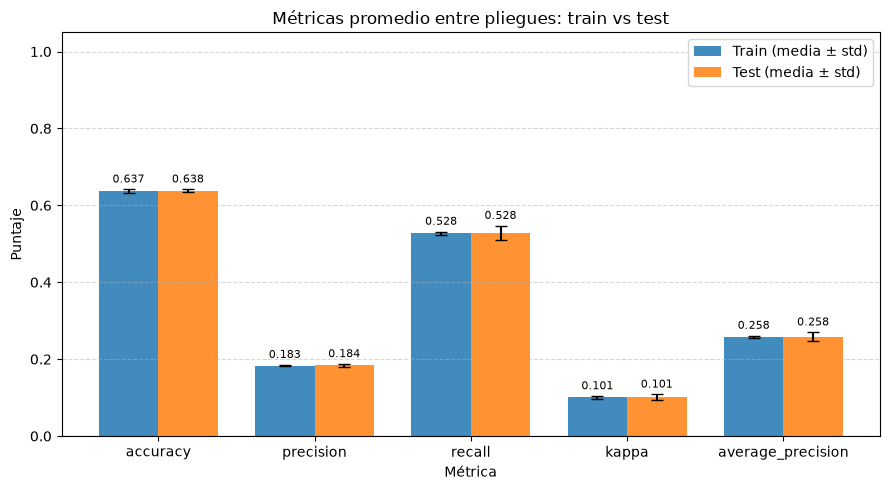

In [26]:
ev_2.comparar_train_test()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

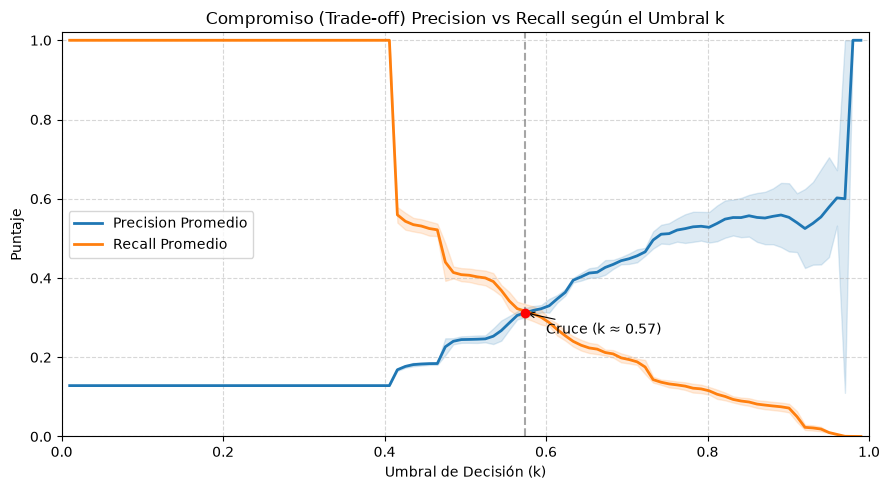

In [27]:
ev_2.curva_umbral()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

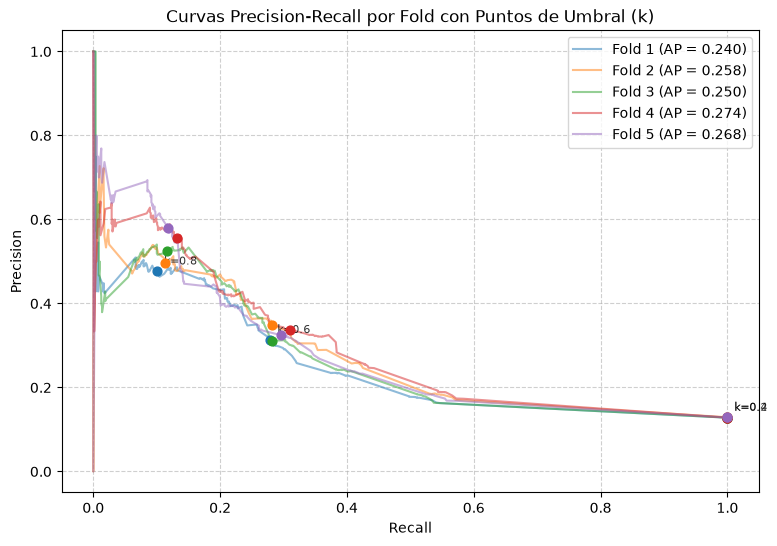

In [28]:
ev_2.curvas_pr()

In [29]:
ev_2.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_alcantarillado,0.414485,0.046169,5,100.0,1.513591,1.428343,1.607440
ORG_analfabetismo,2.675554,0.050107,5,100.0,14.520399,13.349428,15.089316
ORG_fuente_agua_cocinar,0.206307,0.032507,5,100.0,1.229130,1.184615,1.290489
ORG_servicio_sanitario,0.570939,0.098138,5,100.0,1.769927,1.522920,1.966124
ORG_trabajo_infantil,1.003688,0.104150,5,100.0,2.728325,2.449820,3.173045
missingindicator_ORG_trabajo_infantil,-0.255254,0.012490,5,100.0,0.774720,0.765502,0.789940


## Interpretar resultados

En comparación con el modelo anterior y usando un umbral de 0.45 se puede ver que el recall es un poco mejor a costa de una precisión más baja, no obstante prácticamente no cambia el comportamiento de las curvas frente al umbral, además el PR-AUC sigue siendo bajo, por lo mismo se plantea una siguiente iteración utilizando SMOTE y otra usando Oversampling en lugar de repesajes.

La variable ORG_analfabetismo presenta el $\text{AOR}$ más alto ($\approx 14.57$). Al estar medida como una proporción ($[0, 1]$), este valor indica que pasar de un hogar sin analfabetismo ($0\%$) a uno totalmente analfabeto ($100\%$) multiplica por $14.57$ los odds de estar en condición de pobreza, controlando por las demás variables del modelo.

Interpretando un cambio más conservador por ejemplo del 10% se tiene que $$\text{OR}_{\Delta=0.1} = e^{0.1 \times \ln(14.57)} \approx 14.57^{0.1} \approx 1.31$$

Luego un aumento del $10\%$ en el analfabetismo del hogar incrementaría los odds de pobreza en un $31\%$

# Tercera propuesta de Pipeline, usar SMOTE para rebalancear

Se plantea este experimento ante el bajo rendimiento de modelos anteriores. Altera la frontera de decisión en regiones densas de la clase minoritaria, ayudando a la regresión logística a separar mejor los datos cuando el desbalance severo

In [30]:
model_lin_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
cv_sfs_3 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1
)

# Pipeline del selector: escala y rebalancea dentro de cada pliegue interno,
# igual que el modelo final. La imputación ya la hizo el paso anterior, así
# que no se repite aquí. SMOTE corre para cada candidato en cada pliegue
# interno: el CV es más lento que el del modelo 2 (use pickle=True).
sfs_inner_pipeline_3 = ImbPipeline(
    [
        ("scaler", MinMaxScaler()),
        ("rebalance", SMOTE(random_state=RANDOM_STATE)),
        ("model", model_lin_reg),
    ]
)

# Pipeline Principal
smote_log_reg = ImbPipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=sfs_inner_pipeline_3,
                n_features_to_select=6,
                direction="forward",
                scoring="average_precision",
                cv=cv_sfs_3,
                n_jobs=-1,
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("rebalance", SMOTE(random_state=RANDOM_STATE)),
        ("model", model_lin_reg),
    ]
)

## Evaluar con CV

In [31]:
ev_3 = EvaluadorCV(
    smote_log_reg, X_train, y_train, 0.5, grupos_train, pickle=True
)

In [32]:
ev_3.evaluar_cv()

umbral: 0.5
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/d4cdf650b7f34f0903a222f1f39b196c.pkl


In [33]:
ev_3.resumen_metricas()

fit_time: 8.492 ± 0.512
score_time: 0.007 ± 0.001
test_accuracy: 0.763 ± 0.004
test_precision: 0.245 ± 0.008
test_recall: 0.408 ± 0.016
test_kappa: 0.174 ± 0.012
test_average_precision: 0.257 ± 0.012


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

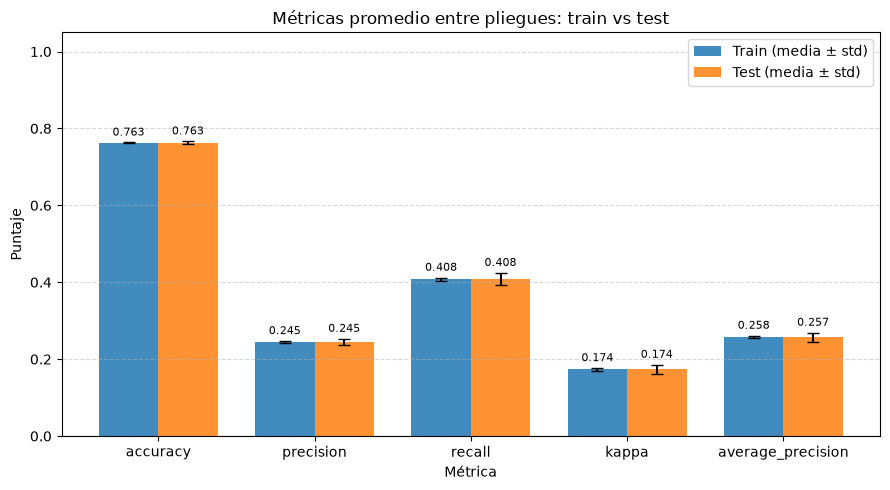

In [34]:
ev_3.comparar_train_test()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

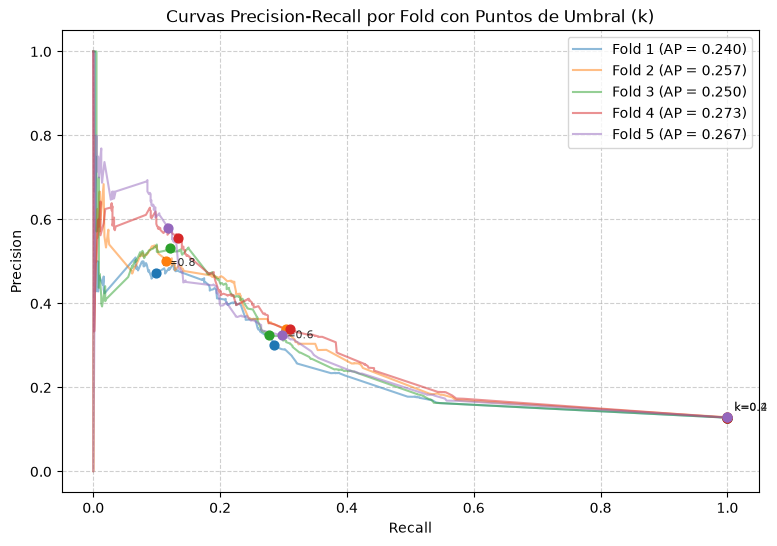

In [35]:
ev_3.curvas_pr()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

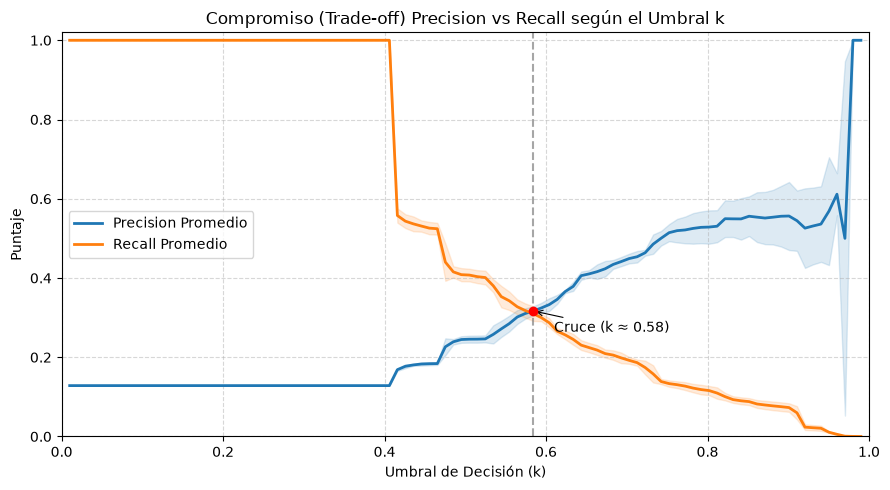

In [36]:
ev_3.curva_umbral()

In [37]:
ev_3.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_alcantarillado,0.417647,0.076383,5,100.0,1.518384,1.399324,1.713364
ORG_analfabetismo,2.702931,0.066832,5,100.0,14.923407,13.250945,15.547845
ORG_fuente_agua_cocinar,0.215448,0.071208,5,100.0,1.240417,1.121870,1.329353
ORG_servicio_sanitario,0.547327,0.169414,5,100.0,1.728626,1.317780,2.060653
ORG_trabajo_infantil,0.988889,0.149977,5,100.0,2.688245,2.253151,3.349264
missingindicator_ORG_trabajo_infantil,-0.261090,0.021251,5,100.0,0.770212,0.752240,0.793126


In [38]:
ev_2.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_alcantarillado,0.414485,0.046169,5,100.0,1.513591,1.428343,1.607440
ORG_analfabetismo,2.675554,0.050107,5,100.0,14.520399,13.349428,15.089316
ORG_fuente_agua_cocinar,0.206307,0.032507,5,100.0,1.229130,1.184615,1.290489
ORG_servicio_sanitario,0.570939,0.098138,5,100.0,1.769927,1.522920,1.966124
ORG_trabajo_infantil,1.003688,0.104150,5,100.0,2.728325,2.449820,3.173045
missingindicator_ORG_trabajo_infantil,-0.255254,0.012490,5,100.0,0.774720,0.765502,0.789940


## Interpretar resultados

En comparación con los modelos anteriores este tiene un rendimiento más balanceado, aunque el recall es más bajo que el del modelo 2 (0.408 vs 0.528), el kappa es mejor por 0.0074, un cambio casi marginal pero que sugiere en qué dirección continuar iterando, el coeficiente de ORG_analfabetismo continúa con el comportamiento de iteraciones anteriores (en los demás coeficientes tampoco parece existir un cambio significativo, en etapas posteriores se verá con pruebas de hipótesis multivariadas para vectores).

# Cuarta propuesta rebalanceo con ADASYN

Más agresivo en las fronteras difusas.

### Analizar fronteras con LDA (acá se usa como explorador, traido de Data Mining, no como modelo)

Hogares con LD1 > 6.74 (fuera del eje): 29


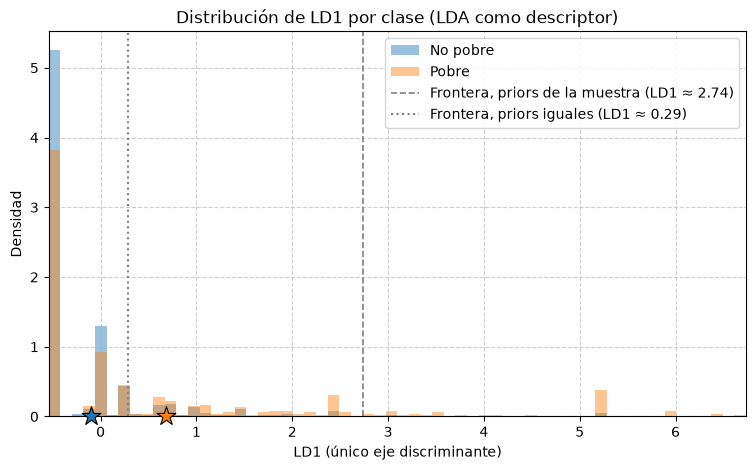

In [39]:
# LDA como descriptor, no como modelo. Con un objetivo binario solo existe
# un eje discriminante (LD1). Se ajusta con todo train porque solo describe.
lda_pipeline = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("lda", LinearDiscriminantAnalysis()),
    ]
)
ld1 = lda_pipeline.fit_transform(X_train, y_train)[:, 0]
lda = lda_pipeline.named_steps["lda"]

# Con un solo eje la varianza explicada siempre es 100 %: no se reporta
coef_ld1 = pd.Series(
    lda.scalings_[:, 0],
    index=lda_pipeline[:-1].get_feature_names_out(),
    name="LD1",
)

# La puntuación de la LDA es lineal en LD1: con esa recta se ubican las
# fronteras sobre el eje
a, b = np.polyfit(ld1, lda_pipeline.decision_function(X_train), 1)
p0, p1 = lda.priors_
frontera = -b / a  # priors de la muestra
frontera_iguales = (np.log(p1 / p0) - b) / a  # priors iguales ("balanced")

clases_lda = {0: ("No pobre", "#1f77b4"), 1: ("Pobre", "#ff7f0e")}

# La cola larga estira el eje: se grafica hasta el percentil 99,9
limite = np.percentile(ld1, 99.9)
bins = np.linspace(ld1.min(), limite, 61)
print(
    f"Hogares con LD1 > {limite:.2f} (fuera del eje): {(ld1 > limite).sum()}"
)

fig, ax = plt.subplots(figsize=(9, 5))

for clase, (nombre, color) in clases_lda.items():
    valores = ld1[y_train.to_numpy() == clase]
    # Cada clase normalizada por separado para que la minoritaria se vea
    ax.hist(
        valores, bins=bins, density=True, alpha=0.45, color=color, label=nombre
    )
    # Media de la clase
    ax.scatter(
        valores.mean(),
        0,
        color=color,
        marker="*",
        s=200,
        edgecolors="black",
        linewidths=0.8,
        zorder=5,
        clip_on=False,
    )

ax.axvline(
    frontera,
    color="grey",
    linestyle="--",
    lw=1.2,
    label=f"Frontera, priors de la muestra (LD1 ≈ {frontera:.2f})",
)
ax.axvline(
    frontera_iguales,
    color="grey",
    linestyle=":",
    lw=1.5,
    label=f"Frontera, priors iguales (LD1 ≈ {frontera_iguales:.2f})",
)

ax.set_xlim(ld1.min(), limite)
ax.set_xlabel("LD1 (único eje discriminante)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de LD1 por clase (LDA como descriptor)")
ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.6)
plt.show()

Note cómo las clases están altamente solapadas, por lo tanto ADASYN puede ser útil.

In [40]:
model_lin_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
cv_sfs_4 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1
)

# Pipeline del selector: escala y rebalancea dentro de cada pliegue interno,
# igual que el modelo final. La imputación ya la hizo el paso anterior, así
# que no se repite aquí. ADASYN corre para cada candidato en cada pliegue
# interno: el CV es más lento que el del modelo 2 (use pickle=True).
sfs_inner_pipeline_4 = ImbPipeline(
    [
        ("scaler", MinMaxScaler()),
        ("rebalance", ADASYN(random_state=RANDOM_STATE)),
        ("model", model_lin_reg),
    ]
)

# Pipeline Principal
adasyn_log_reg = ImbPipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=sfs_inner_pipeline_4,
                n_features_to_select=6,
                direction="forward",
                scoring="average_precision",
                cv=cv_sfs_4,
                n_jobs=-1,
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("rebalance", ADASYN(random_state=RANDOM_STATE)),
        ("model", model_lin_reg),
    ]
)

## Evaluar con CV

In [41]:
ev_4 = EvaluadorCV(
    adasyn_log_reg, X_train, y_train, UMBRAL, grupos_train, pickle=True
)

In [42]:
ev_4.evaluar_cv()

umbral: 0.5
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/1f9fa55738de449a8d4dddd7a0567922.pkl


In [43]:
ev_4.resumen_metricas()

fit_time: 12.349 ± 0.796
score_time: 0.007 ± 0.001
test_accuracy: 0.769 ± 0.013
test_precision: 0.249 ± 0.019
test_recall: 0.394 ± 0.018
test_kappa: 0.175 ± 0.023
test_average_precision: 0.254 ± 0.011


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

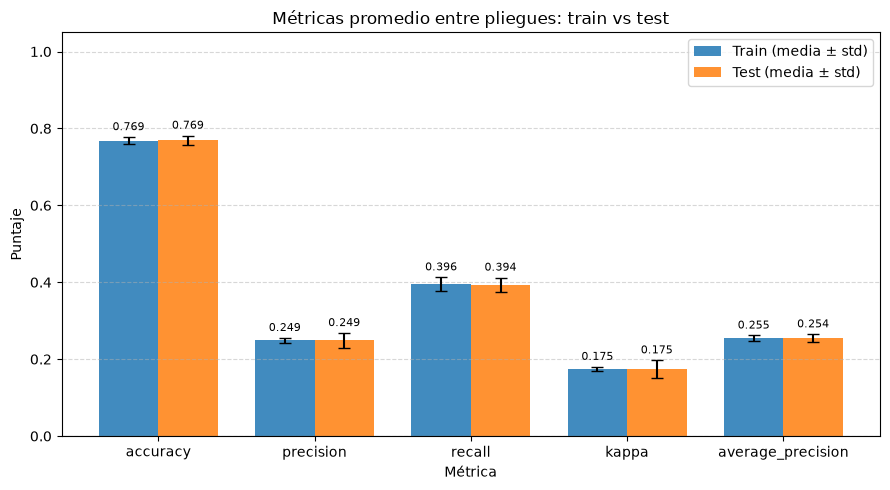

In [44]:
ev_4.comparar_train_test()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

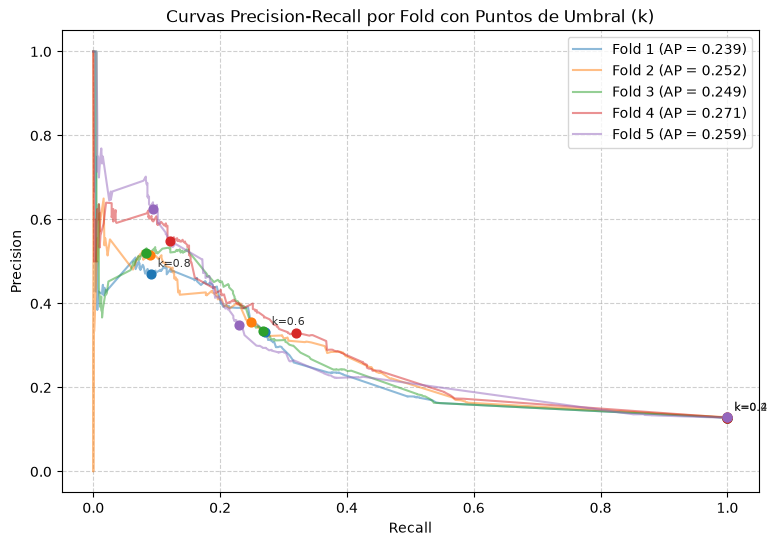

In [45]:
ev_4.curvas_pr()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

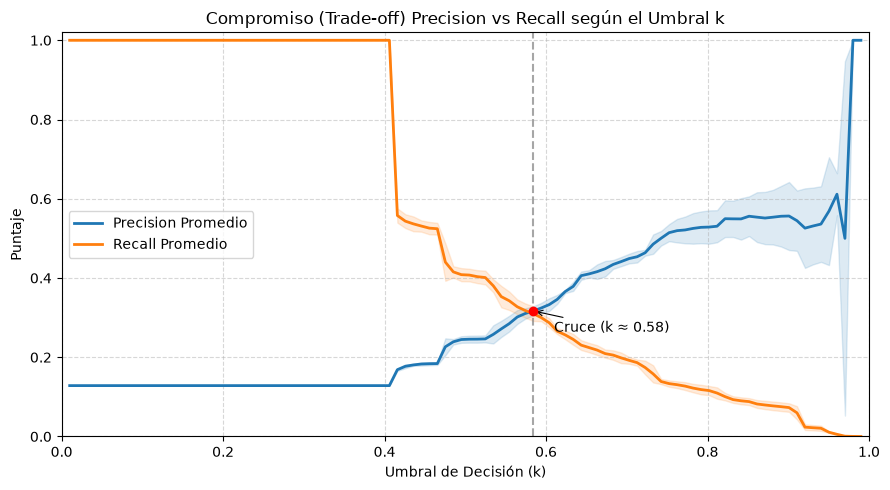

In [46]:
ev_3.curva_umbral()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

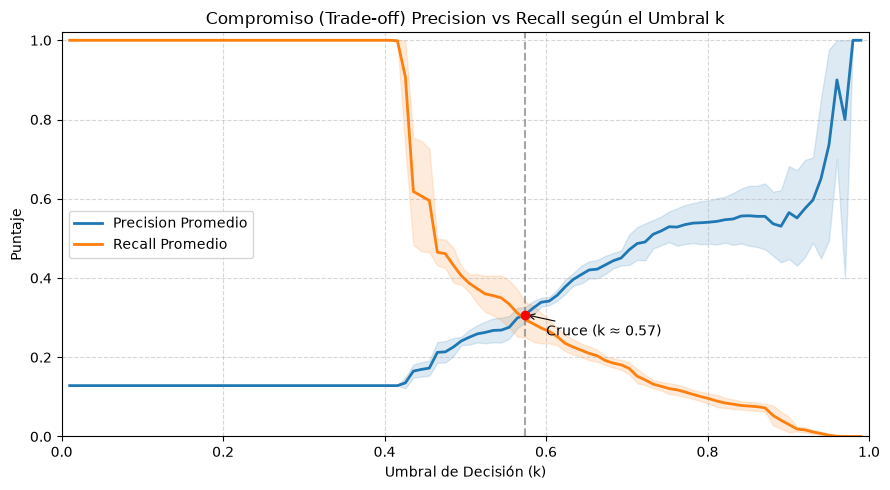

In [47]:
ev_4.curva_umbral()

In [48]:
ev_4.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_analfabetismo,2.333734,0.178257,5,100.0,10.316386,8.082194,13.032701
ORG_fuente_agua_cocinar,0.128034,0.162634,5,100.0,1.136591,0.896991,1.325877
ORG_servicio_sanitario,0.597295,0.475851,5,100.0,1.817197,1.230333,3.428109
ORG_trabajo_infantil,0.856090,0.191980,5,100.0,2.353939,1.753711,2.854023
missingindicator_ORG_trabajo_infantil,-0.114099,0.140156,5,100.0,0.892169,0.786794,1.113491
ORG_alcantarillado,0.479012,0.012945,3,60.0,1.614479,1.592245,1.633588
ORG_acueducto,0.321544,NaN,1,20.0,1.379256,1.379256,1.379256
ORG_sin_aseguramiento,0.027807,NaN,1,20.0,1.028198,1.028198,1.028198


In [49]:
# Metricas con umbral 0.45
# Se recalculan con las probabilidades fuera de muestra que ya guardó
# evaluar_cv(): mismos números que con un EvaluadorCV nuevo, sin reentrenar
umbral_045 = 0.45
metricas_umbral = {
    "accuracy": custom_accuracy,
    "precision": custom_precision,
    "recall": custom_recall,
    "kappa": custom_kappa,
}

por_fold = pd.DataFrame(
    {
        f"test_{nombre}": [
            funcion(y_te, y_proba, umbral_045)
            for y_te, y_proba in ev_4.probas_cv
        ]
        for nombre, funcion in metricas_umbral.items()
    }
)
# Proporción de hogares que el pliegue clasifica como pobres
por_fold["pred_pobre"] = [
    np.mean(y_proba >= umbral_045) for _, y_proba in ev_4.probas_cv
]
# AP no depende del umbral: es la misma de evaluar_cv()
por_fold["test_average_precision"] = ev_4.scores["test_average_precision"]
por_fold.index = pd.RangeIndex(1, len(por_fold) + 1, name="fold")

# Mismo formato que resumen_metricas (np.std, ddof=0)
print(f"umbral: {umbral_045}")
for metric, val in por_fold.items():
    print(f"{metric}: {np.mean(val):.3f} ± {np.std(val):.3f}")
por_fold.round(3)

umbral: 0.45
test_accuracy: 0.551 ± 0.145
test_precision: 0.170 ± 0.018
test_recall: 0.603 ± 0.136
test_kappa: 0.077 ± 0.033
pred_pobre: 0.475 ± 0.180
test_average_precision: 0.254 ± 0.011


,test_accuracy,test_precision,test_recall,test_kappa,pred_pobre,test_average_precision
fold,,,,,,
1,0.643,0.179,0.498,0.092,0.357,0.239
2,0.586,0.170,0.571,0.079,0.433,0.252
3,0.646,0.184,0.511,0.101,0.356,0.249
4,0.617,0.181,0.564,0.099,0.399,0.271
5,0.265,0.135,0.870,0.013,0.830,0.259


## Interpretar resultados

Las métricas no cambiaron mucho respecto a la iteración anterior (SMOTE, umbral 0.5): la precisión bajó un poco (0.245 → 0.233), el recall subió (0.408 → 0.421) y el kappa bajó (0.174 → 0.158). El PR-AUC es prácticamente el mismo (0.256 vs 0.257), es decir, ADASYN no ordena mejor a los hogares, solo desplaza las probabilidades.

Lo que sí cambió es la estabilidad entre pliegues: las desviaciones estándar son cerca de 10 veces mayores (accuracy ±0.049 vs ±0.004, kappa ±0.035 vs ±0.012).

Con umbral 0.45 esto se vuelve evidente: accuracy 0.530 ± 0.185, precisión 0.169 ± 0.019, recall 0.625 ± 0.177 y kappa 0.075 ± 0.036. Es decir, a pesar de que la curva es más suave las métricas varían tanto que es preferible usar SMOTE que hasta el momento ha sido el mejor.

# Quinta propuesta rebalanceo con submuestreo (RandomUnderSampler)

Elimina al azar hogares de la clase mayoritaria (no pobres) hasta que ambas clases tengan el mismo tamaño. Solo actúa durante el `fit`, así que nunca toca los pliegues de evaluación.

In [50]:
model_lin_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
cv_sfs_5 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1
)

# Pipeline del selector: escala y rebalancea dentro de cada pliegue interno,
# igual que el modelo final. La imputación ya la hizo el paso anterior, así
# que no se repite aquí. El submuestreo entrena con menos filas, así que el
# CV debería ser más rápido que con SMOTE o ADASYN.
sfs_inner_pipeline_5 = ImbPipeline(
    [
        ("scaler", MinMaxScaler()),
        ("rebalance", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", model_lin_reg),
    ]
)

# Pipeline Principal
under_log_reg = ImbPipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=sfs_inner_pipeline_5,
                n_features_to_select=6,
                direction="forward",
                scoring="average_precision",
                cv=cv_sfs_5,
                n_jobs=-1,
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("rebalance", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", model_lin_reg),
    ]
)

## Evaluar con CV

In [51]:
ev_5 = EvaluadorCV(
    under_log_reg, X_train, y_train, UMBRAL, grupos_train, pickle=True
)

In [52]:
ev_5.evaluar_cv()

umbral: 0.5
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/7f654e528a2667f0a7d6bde8fb1dc20d.pkl


In [53]:
ev_5.resumen_metricas()

fit_time: 7.121 ± 0.468
score_time: 0.009 ± 0.000
test_accuracy: 0.763 ± 0.004
test_precision: 0.244 ± 0.009
test_recall: 0.405 ± 0.021
test_kappa: 0.172 ± 0.014
test_average_precision: 0.258 ± 0.014


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

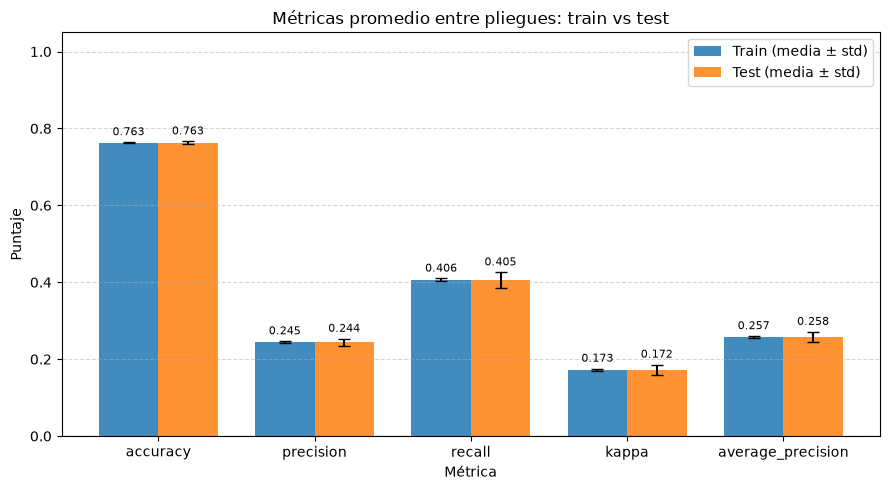

In [54]:
ev_5.comparar_train_test()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

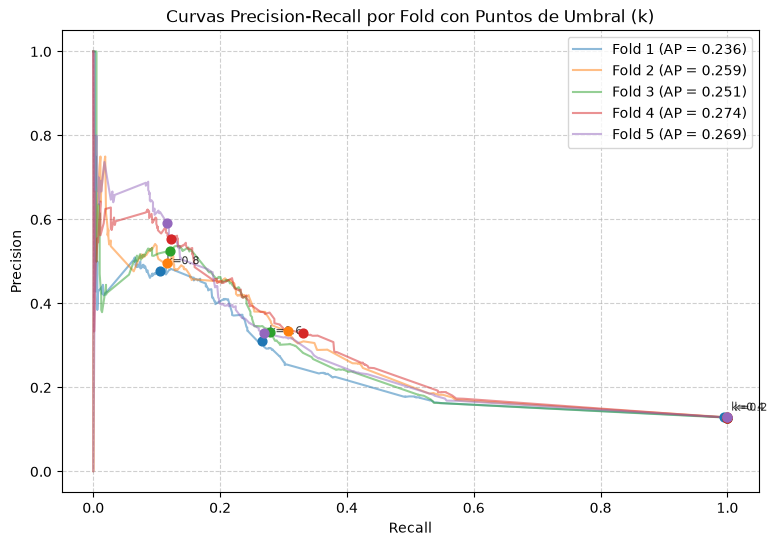

In [55]:
ev_5.curvas_pr()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

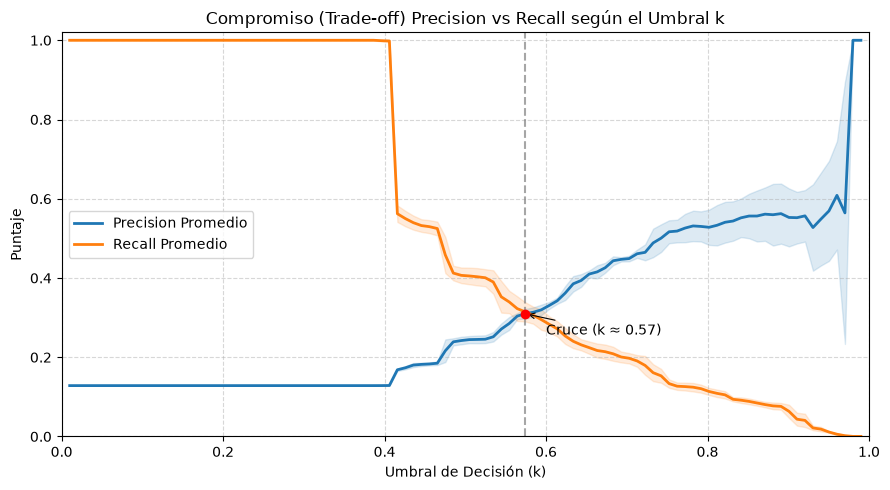

In [56]:
ev_5.curva_umbral()

In [57]:
ev_5.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_alcantarillado,0.399878,0.024423,5,100.0,1.491643,1.438667,1.529000
ORG_analfabetismo,2.738439,0.173519,5,100.0,15.462835,12.861162,19.221030
ORG_fuente_agua_cocinar,0.242860,0.036406,5,100.0,1.274890,1.218993,1.344811
ORG_servicio_sanitario,0.598233,0.054269,5,100.0,1.818903,1.716983,1.983606
missingindicator_ORG_trabajo_infantil,-0.256934,0.033699,5,100.0,0.773419,0.749304,0.803800
ORG_trabajo_infantil,0.970038,0.249519,4,80.0,2.638045,1.832987,3.165729
ORG_sin_aseguramiento,-0.050989,NaN,1,20.0,0.950289,0.950289,0.950289


In [58]:
ev_3.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_alcantarillado,0.417647,0.076383,5,100.0,1.518384,1.399324,1.713364
ORG_analfabetismo,2.702931,0.066832,5,100.0,14.923407,13.250945,15.547845
ORG_fuente_agua_cocinar,0.215448,0.071208,5,100.0,1.240417,1.121870,1.329353
ORG_servicio_sanitario,0.547327,0.169414,5,100.0,1.728626,1.317780,2.060653
ORG_trabajo_infantil,0.988889,0.149977,5,100.0,2.688245,2.253151,3.349264
missingindicator_ORG_trabajo_infantil,-0.261090,0.021251,5,100.0,0.770212,0.752240,0.793126


## Interpretar resultados

El modelo se comportó similar al de la tercera propuesta, las métricas tienen cambios marginales de un modelo a otro, pero este eliminó información y por eso se confia un poco menos en sus coeficientes, además el de ORG_analfabetismo pasó a ser 15.46 y tener mayor desviación (cuantificada en el coef), ya que SMOTE rinde similar y consideró todos los datos se sigue posicionando como ganador.

# Sexta propuesta: Regresión Logística L1 (Lasso) con selección embebida

En lugar del selector secuencial, la penalización L1 lleva a cero los coeficientes de las variables menos útiles y `SelectFromModel` conserva solo las que quedan distintas de cero. Luego se reajusta una regresión logística L2 con esas variables ("relaxed lasso"), así el coeficiente final no queda encogido por la penalización.

Se usa `StandardScaler` porque la penalización depende de la escala: sin estandarizar, las variables con rango pequeño se penalizan más.

**Puesto que aún no se ha estudiado las penalizaciones en el curso se plantea una breve explicación teórica:**

Las regularizaciones son técnicas que plantean reducir coeficientes muy grandes, esto en pro de aumentar la estabilidad de estos y evitar el sobreajuste, son 2 los tipos principales de regularización L1 y L2.

La regularización L2 (Ridge) agrega al RSS un factor o parámetro de penalización $\lambda$ (en regresión logística lo hace sobre binary cross entropy), conforme este es más grande los coeficientes se acercan cada vez más a 0 (la reducción a 0 que se comentaba anteriormente).

Mientras que el mecanismo de L1 (Lasso) consta en volver estrictamente 0 a los penalizados, en términos generales elimina primero las que son ruido (se detecta mediante la optimización de $\|\mathbf{y} - \mathbf{X}\boldsymbol{\beta}\|_2^2 + \lambda \sum_{j=1}^{p} |\beta_j| = \text{RSS}(\boldsymbol{\beta}) + \lambda \|\boldsymbol{\beta}\|_1$ , esto en regresión lineal, en la logística de nuevo se hace sobre binary cross entropy)

Justo de ahí viene la arquitectura propuesta, primero Lasso se encarga de seleccionar las variables, llevando a 0 aquellas que solo aportan ruido, y posteriormente con ese nuevo subconjunto se entrena una regresión logística de tal manera que Ridge controla la divergencia de los coeficientes y estabiliza el cálculo (no ve en `model_log_reg_6` la declaración explicita de Ridge ya que LogisticRegression lo implementa por defecto)

> La lectura de los AOR se mantiene igual, aunque haciendo la salvedad de que está regularizado.

> Se usa estandarización por la importancia que el método le da a las escalas de los coef

> scikit-learn regulariza la logística por defecto, y lo parametriza al revés: con
C = 1/λ, de modo que C grande es poca regularización y C chico es mucha.

<small><b>Basado en el bloque nueve del material de clase.</b></small>

In [59]:
1 / 0.01  # esta es la lambda

100.0

In [60]:
# Selector: Lasso (l1_ratio=1 equivale a penalty="l1", que está obsoleto
# desde scikit-learn 1.8)
lasso_selector = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    C=0.01,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
model_log_reg_6 = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE
)

# Pipeline Principal
lasso_log_reg = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        ("scaler", StandardScaler()),
        ("select_vars", SelectFromModel(lasso_selector)),
        ("model", model_log_reg_6),
    ]
)

## Evaluar con CV

In [61]:
ev_6 = EvaluadorCV(
    lasso_log_reg, X_train, y_train, UMBRAL, grupos_train, pickle=True
)

In [62]:
ev_6.evaluar_cv()

umbral: 0.5
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/5953d6aa9f47e96eb3c91e041166b6c4.pkl


In [63]:
ev_6.resumen_metricas()

fit_time: 0.023 ± 0.002
score_time: 0.006 ± 0.000
test_accuracy: 0.762 ± 0.005
test_precision: 0.243 ± 0.008
test_recall: 0.405 ± 0.016
test_kappa: 0.171 ± 0.012
test_average_precision: 0.256 ± 0.012


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

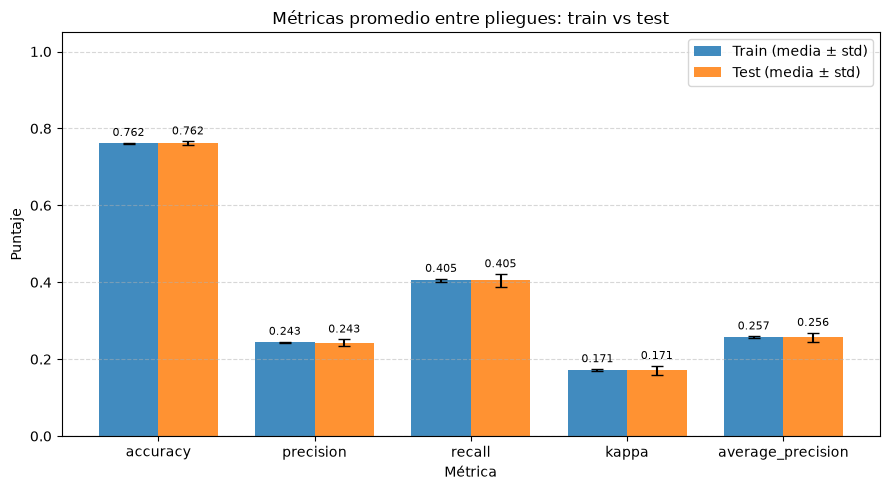

In [64]:
ev_6.comparar_train_test()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

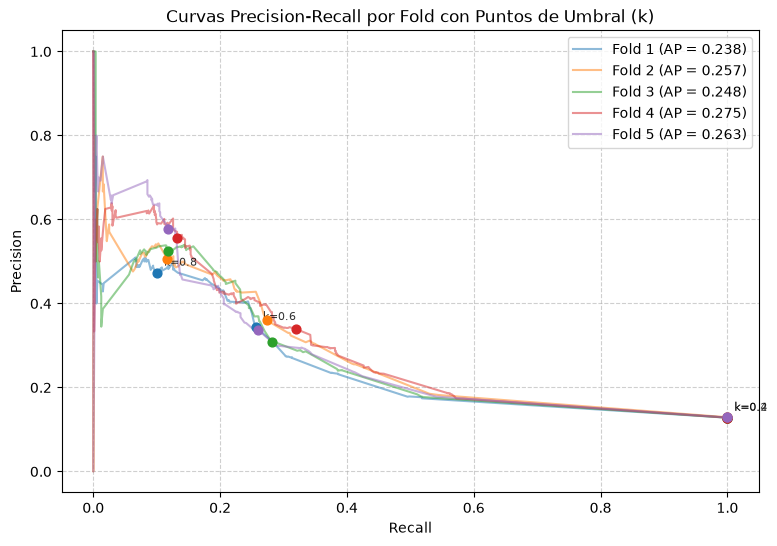

In [65]:
ev_6.curvas_pr()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

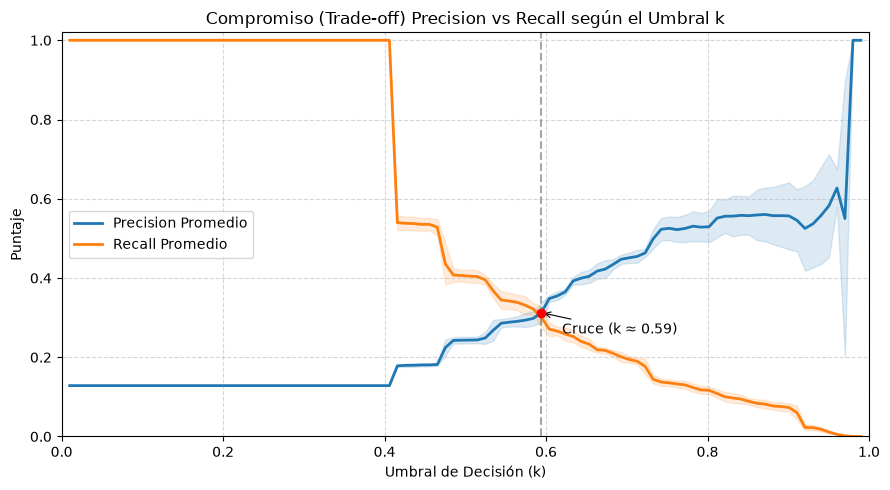

In [66]:
ev_6.curva_umbral()

In [67]:
ev_6.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_acueducto,0.065988,0.010039,5,100.0,1.068214,1.053338,1.081415
ORG_alcantarillado,0.131347,0.015877,5,100.0,1.140364,1.123210,1.165013
ORG_analfabetismo,0.412281,0.006969,5,100.0,1.510258,1.494319,1.520134
ORG_servicio_sanitario,0.091419,0.016436,5,100.0,1.095728,1.069991,1.115863
ORG_trabajo_infantil,0.090249,0.009092,5,100.0,1.094446,1.083824,1.109283
missingindicator_ORG_trabajo_infantil,-0.104011,0.004857,5,100.0,0.901215,0.897794,0.908291
missingindicator_ORG_analfabetismo,0.032657,0.000516,4,80.0,1.033196,1.032649,1.033919
ORG_fuente_agua_cocinar,0.008370,NaN,1,20.0,1.008405,1.008405,1.008405


## Interpretar resultados

Las métricas no tienen un gran cambio respecto a iteraciones anteriores.

# Séptima propuesta: Naive Bayes Bernoulli (presencia de privación)

Después de `MinMaxScaler` el 0 de cada variable es la mejor categoría (o ningún miembro afectado), así que `BernoulliNB(binarize=0.0)` convierte cada variable en "¿el hogar tiene alguna privación en esto?". Se pierde la intensidad de la privación a cambio de un modelo más simple, coherente con la lógica de conteo de privaciones del IPM.

- Rebalanceo con los priors: `class_prior=[0.5, 0.5]`.

In [68]:
model_bnb = BernoulliNB(binarize=0.0, class_prior=[0.5, 0.5])  # X > 0 --> 1
cv_sfs_7 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1
)

# Pipeline del selector: escala dentro de cada pliegue interno, igual que
# el modelo final. La imputación ya la hizo el paso anterior.
sfs_inner_pipeline_7 = Pipeline(
    [
        ("scaler", MinMaxScaler()),
        ("model", model_bnb),
    ]
)

# Pipeline Principal
bnb_privacion = Pipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=sfs_inner_pipeline_7,
                n_features_to_select=6,
                direction="forward",
                scoring="average_precision",
                cv=cv_sfs_7,
                n_jobs=-1,
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("model", model_bnb),
    ]
)

## Evaluar con CV

In [69]:
ev_7 = EvaluadorCV(
    bnb_privacion, X_train, y_train, UMBRAL, grupos_train, pickle=True
)

In [70]:
ev_7.evaluar_cv()

umbral: 0.5
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/40437875c4ccc8db31392d6b9b7a7e14.pkl


In [71]:
ev_7.resumen_metricas()

fit_time: 7.050 ± 0.447
score_time: 0.008 ± 0.000
test_accuracy: 0.747 ± 0.007
test_precision: 0.233 ± 0.007
test_recall: 0.422 ± 0.017
test_kappa: 0.162 ± 0.009
test_average_precision: 0.248 ± 0.014


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

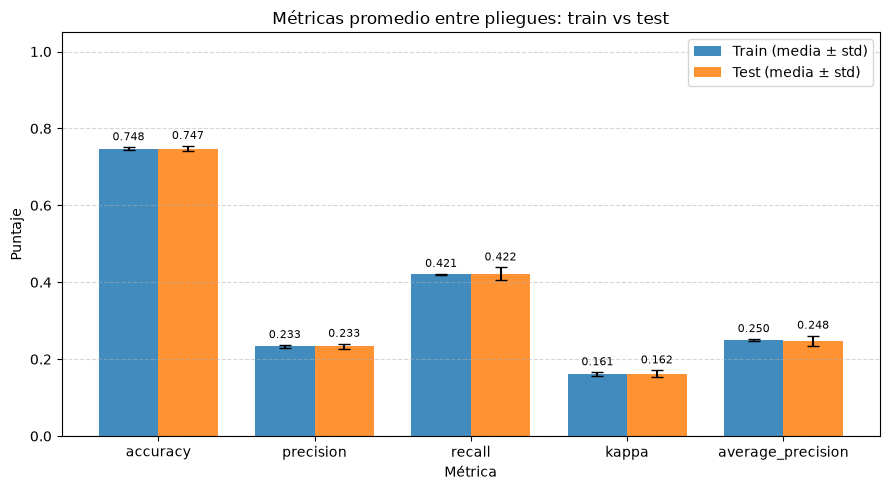

In [72]:
ev_7.comparar_train_test()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

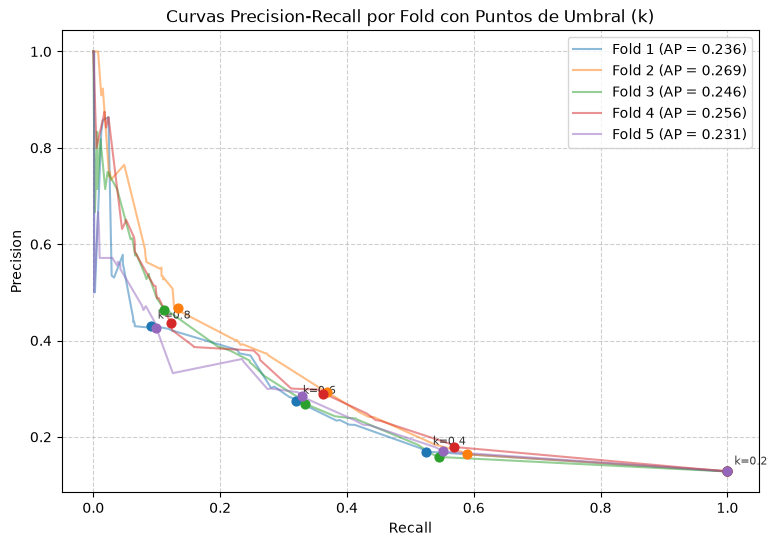

In [73]:
ev_7.curvas_pr()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

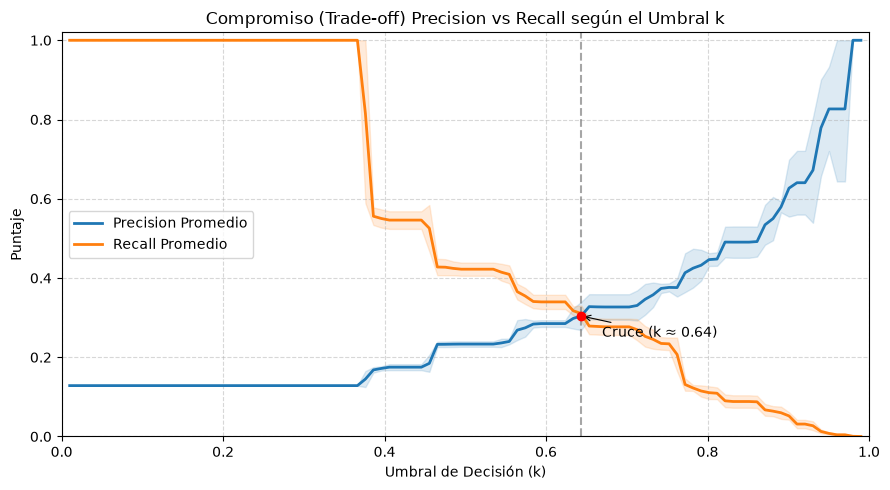

In [74]:
ev_7.curva_umbral()

In [75]:
ev_7.frecuencia_variables()

--- Frecuencia de selección de variables (5 Folds) ---
                             Variable  Frecuencia  Porcentaje
                    ORG_analfabetismo           5       100.0
                 ORG_trabajo_infantil           5       100.0
                ORG_sin_aseguramiento           5       100.0
missingindicator_ORG_trabajo_infantil           5       100.0
                        ORG_acueducto           3        60.0
               ORG_servicio_sanitario           3        60.0
                   ORG_alcantarillado           2        40.0
              ORG_fuente_agua_cocinar           2        40.0


,Variable,Frecuencia,Porcentaje
0,ORG_analfabetismo,5,100.0
1,ORG_trabajo_infantil,5,100.0
2,ORG_sin_aseguramiento,5,100.0
3,missingindicator_ORG_trabajo_infantil,5,100.0
4,ORG_acueducto,3,60.0
5,ORG_servicio_sanitario,3,60.0
6,ORG_alcantarillado,2,40.0
7,ORG_fuente_agua_cocinar,2,40.0


## Interpretar resultados

Tiene un rendimiento que en líneas generales es similar a los demás modelos, pero perdiendo la explicabilidad que las demás regresiones logísticas ofrecen.

# Octava propuesta: KNN con submuestreo

KNN clasifica por distancia.

In [76]:
model_knn = KNeighborsClassifier(n_neighbors=51)
cv_sfs_8 = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1
)

# Pipeline del selector: escala y rebalancea dentro de cada pliegue interno,
# igual que el modelo final. La imputación ya la hizo el paso anterior.
sfs_inner_pipeline_8 = ImbPipeline(
    [
        ("scaler", MinMaxScaler()),
        ("rebalance", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", model_knn),
    ]
)

# Pipeline Principal
knn_under = ImbPipeline(
    [
        (
            "imputer",
            SimpleImputer(
                strategy="constant", fill_value=0, add_indicator=True
            ),
        ),
        (
            "select_vars",
            SequentialFeatureSelector(
                estimator=sfs_inner_pipeline_8,
                n_features_to_select=6,
                direction="forward",
                scoring="average_precision",
                cv=cv_sfs_8,
                n_jobs=-1,
            ),
        ),
        ("scaler", MinMaxScaler()),
        ("rebalance", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("model", model_knn),
    ]
)

## Evaluar con CV

In [77]:
ev_8 = EvaluadorCV(
    knn_under, X_train, y_train, UMBRAL, grupos_train, pickle=True
)

In [78]:
ev_8.evaluar_cv()

umbral: 0.5
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/23eb7cb2d9d0e0a9c0d32003490cb2ea.pkl


In [79]:
ev_8.resumen_metricas()

fit_time: 10.254 ± 0.794
score_time: 0.125 ± 0.006
test_accuracy: 0.825 ± 0.009
test_precision: 0.312 ± 0.019
test_recall: 0.300 ± 0.019
test_kappa: 0.205 ± 0.016
test_average_precision: 0.223 ± 0.010


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

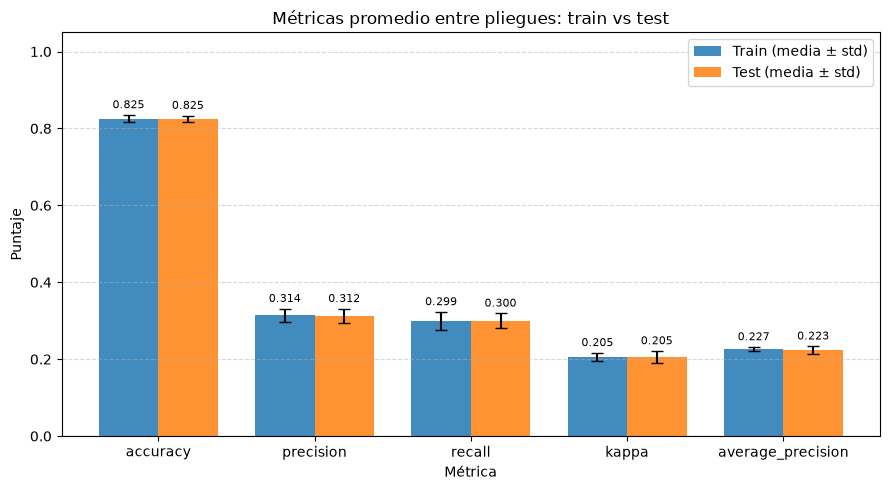

In [80]:
ev_8.comparar_train_test()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

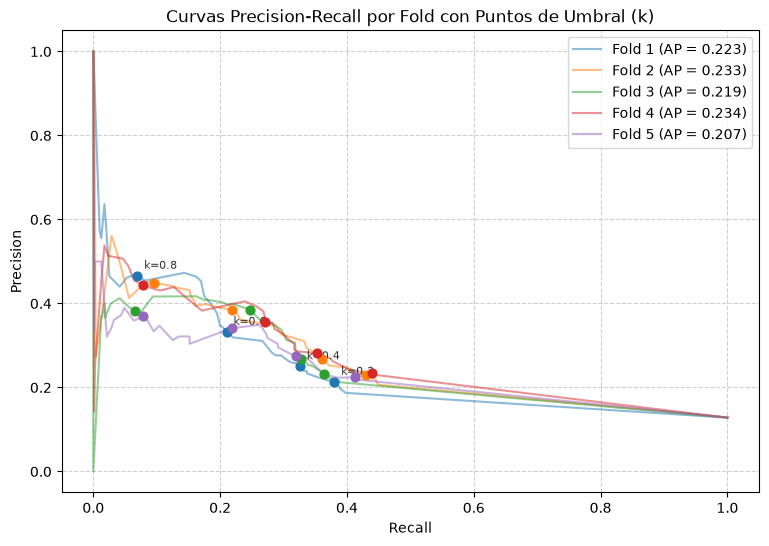

In [81]:
ev_8.curvas_pr()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

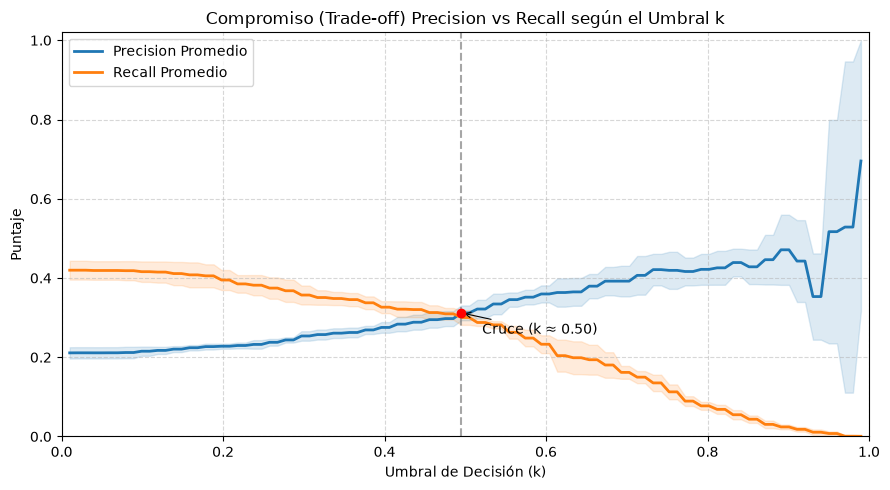

In [82]:
ev_8.curva_umbral()

In [83]:
ev_8.frecuencia_variables()

--- Frecuencia de selección de variables (5 Folds) ---
                             Variable  Frecuencia  Porcentaje
                    ORG_analfabetismo           5       100.0
                ORG_sin_aseguramiento           5       100.0
              ORG_fuente_agua_cocinar           5       100.0
               ORG_servicio_sanitario           5       100.0
missingindicator_ORG_trabajo_infantil           5       100.0
                        ORG_acueducto           2        40.0
   missingindicator_ORG_analfabetismo           2        40.0
                 ORG_trabajo_infantil           1        20.0


,Variable,Frecuencia,Porcentaje
0,ORG_analfabetismo,5,100.0
1,ORG_sin_aseguramiento,5,100.0
2,ORG_fuente_agua_cocinar,5,100.0
3,ORG_servicio_sanitario,5,100.0
4,missingindicator_ORG_trabajo_infantil,5,100.0
5,ORG_acueducto,2,40.0
6,missingindicator_ORG_analfabetismo,2,40.0
7,ORG_trabajo_infantil,1,20.0


## Precisión y Recall según n_neighbors

Se reutilizan los pliegues de `ev_8` y las variables que el SFS eligió en cada uno (con k = 51): solo se reentrenan el escalado, el submuestreo y el KNN para cada valor de k. Por eso la curva mide la sensibilidad a k con las variables fijas, no lo que pasaría si el SFS se repitiera con cada k.

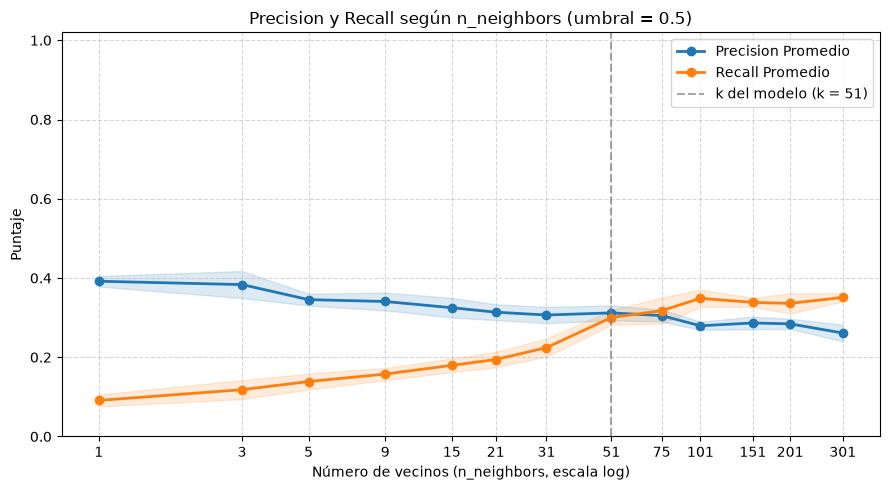

In [84]:
# Valores impares de k: con umbral 0.5 no hay empates en la votación
k_vecinos = [1, 3, 5, 9, 15, 21, 31, 51, 75, 101, 151, 201, 301]

precisions_per_k = []
recalls_per_k = []

# Pliegues que ya usó evaluar_cv(): mismos train/test, sin repetir el SFS
for estimador, idx_tr, idx_te in zip(
    ev_8.scores["estimator"],
    ev_8.scores["indices"]["train"],
    ev_8.scores["indices"]["test"],
):
    # Imputación y selección ya ajustadas en este pliegue
    preparar = estimador[:2]
    x_tr = preparar.transform(X_train.iloc[idx_tr])
    x_te = preparar.transform(X_train.iloc[idx_te])
    y_tr = y_train.iloc[idx_tr]
    y_te = y_train.iloc[idx_te]

    fold_precisions = []
    fold_recalls = []
    for k in k_vecinos:
        # Escalado + submuestreo + KNN sin ajustar, con otro k
        knn_k = clone(estimador[2:]).set_params(model__n_neighbors=k)
        knn_k.fit(x_tr, y_tr)
        y_proba = knn_k.predict_proba(x_te)[:, 1]
        fold_precisions.append(custom_precision(y_te, y_proba, UMBRAL))
        fold_recalls.append(custom_recall(y_te, y_proba, UMBRAL))

    precisions_per_k.append(fold_precisions)
    recalls_per_k.append(fold_recalls)

# Promediar a través de los folds
mean_precision = np.mean(precisions_per_k, axis=0)
std_precision = np.std(precisions_per_k, axis=0)
mean_recall = np.mean(recalls_per_k, axis=0)
std_recall = np.std(recalls_per_k, axis=0)

fig, ax = plt.subplots(figsize=(9, 5))

# Curva de Precision
ax.plot(
    k_vecinos,
    mean_precision,
    marker="o",
    label="Precision Promedio",
    color="#1f77b4",
    lw=2,
)
ax.fill_between(
    k_vecinos,
    np.clip(mean_precision - std_precision, 0, 1),
    np.clip(mean_precision + std_precision, 0, 1),
    color="#1f77b4",
    alpha=0.15,
)

# Curva de Recall
ax.plot(
    k_vecinos,
    mean_recall,
    marker="o",
    label="Recall Promedio",
    color="#ff7f0e",
    lw=2,
)
ax.fill_between(
    k_vecinos,
    np.clip(mean_recall - std_recall, 0, 1),
    np.clip(mean_recall + std_recall, 0, 1),
    color="#ff7f0e",
    alpha=0.15,
)

# k del modelo evaluado
k_actual = ev_8.pipeline.named_steps["model"].n_neighbors
ax.axvline(
    x=k_actual,
    color="grey",
    linestyle="--",
    alpha=0.7,
    label=f"k del modelo (k = {k_actual})",
)

ax.set_xscale("log")
ax.set_xticks(k_vecinos, labels=[str(k) for k in k_vecinos])
ax.minorticks_off()
ax.set_xlabel("Número de vecinos (n_neighbors, escala log)")
ax.set_ylabel("Puntaje")
ax.set_title(f"Precision y Recall según n_neighbors (umbral = {UMBRAL})")
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

## Interpretar resultados

El modelo rinde mucho peor que los de iteraciones pasadas.

# Comparación global de modelos

Se comparan todos los modelos evaluados con validación cruzada, más la línea base (dummy):

- **Mismos pliegues**: todos usan el separador por defecto de `EvaluadorCV`, así que las diferencias no vienen de particiones distintas (se verifica en la celda siguiente).
- **Umbral común de 0.5** para accuracy, precision, recall y kappa: se recalculan con las probabilidades fuera de muestra que ya guardó cada modelo, sin reentrenar. Los modelos 1 y 2 se evaluaron con 0.45 en sus secciones, así que aquí sus números cambian. El PR-AUC (average precision) no depende del umbral.
- **Dos intervalos**:
  - *Media ± desviación estándar* entre los 5 pliegues (`np.std`, igual que `resumen_metricas`): qué tanto varía el modelo de un pliegue a otro.
  - *IC del 95 % por bootstrap*: `EvaluadorCV.bootstrap_ic` junta las predicciones fuera de muestra y remuestrea segmentos completos (`SEGMENTO`) con reemplazo 1000 veces; el IC son los percentiles 2.5 y 97.5 de esa distribución empírica. Se remuestrean segmentos y no hogares porque los hogares de un mismo segmento están correlacionados. Todos los modelos reciben las mismas réplicas (comparación pareada). El tiempo de ajuste no tiene IC.

In [85]:
# Línea base con la misma clase: comparte pliegues con los demás modelos
ev_0 = EvaluadorCV(
    dummy_model_pipeline, X_train, y_train, UMBRAL, grupos_train, pickle=True
).evaluar_cv()

MODELOS = {
    "0 Dummy": ev_0,
    "1 LR pesos": ev,
    "2 LR pesos MinMax": ev_2,
    "3 LR SMOTE": ev_3,
    "4 LR ADASYN": ev_4,
    "5 LR submuestreo": ev_5,
    "6 LR Lasso": ev_6,
    "7 Bernoulli NB": ev_7,
    "8 KNN submuestreo": ev_8,
}
NOMBRE_BASE = "0 Dummy"
UMBRAL_COMPARACION = 0.5

# Todos usan el separador por defecto de EvaluadorCV: mismos pliegues
for nombre, ev_m in MODELOS.items():
    for idx_m, idx_0 in zip(
        ev_m.scores["indices"]["test"], ev_0.scores["indices"]["test"]
    ):
        assert np.array_equal(idx_m, idx_0), f"{nombre}: otros pliegues"

umbral: 0.5
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/e314709fab7da2b34d9e320ef72622a5.pkl


In [86]:
METRICAS_UMBRAL = {
    "accuracy": custom_accuracy,
    "precision": custom_precision,
    "recall": custom_recall,
    "kappa": custom_kappa,
}
METRICAS_IC = [*METRICAS_UMBRAL, "average_precision"]
METRICAS = [*METRICAS_IC, "fit_time"]

# Métricas por pliegue con el umbral común (sin reentrenar)
filas = []
for nombre, ev_m in MODELOS.items():
    for fold, (y_te, y_proba) in enumerate(ev_m.probas_cv):
        fila = {"modelo": nombre, "fold": fold + 1}
        for metrica, funcion in METRICAS_UMBRAL.items():
            fila[metrica] = funcion(y_te, y_proba, UMBRAL_COMPARACION)
        fila["average_precision"] = average_precision_score(y_te, y_proba)
        fila["fit_time"] = ev_m.scores["fit_time"][fold]
        filas.append(fila)
df_folds = pd.DataFrame(filas)

# Media ± desviación estándar entre pliegues (ddof=0, como
# resumen_metricas)
resumen_std = (
    df_folds.melt(
        id_vars=["modelo", "fold"], var_name="metrica", value_name="valor"
    )
    .groupby(["modelo", "metrica"], sort=False)["valor"]
    .agg(media="mean", std=lambda v: v.std(ddof=0))
)
resumen_std["std_inf"] = resumen_std["media"] - resumen_std["std"]
resumen_std["std_sup"] = resumen_std["media"] + resumen_std["std"]

# IC del 95 % por bootstrap de segmentos (1000 réplicas por modelo)
resumen_ic = pd.concat(
    {
        nombre: ev_m.bootstrap_ic(umbral=UMBRAL_COMPARACION)
        for nombre, ev_m in MODELOS.items()
    },
    names=["modelo"],
)

## Tablas

Primero la media ± desviación estándar entre pliegues (el tiempo de ajuste en segundos); luego la estimación con todas las predicciones juntas y su IC del 95 % por bootstrap.

In [87]:
decimales = np.where(
    resumen_std.index.get_level_values("metrica") == "fit_time", 1, 3
)
texto_std = [
    f"{media:.{d}f} ± {std:.{d}f}"
    for media, std, d in zip(
        resumen_std["media"], resumen_std["std"], decimales
    )
]
tabla_std = (
    pd.Series(texto_std, index=resumen_std.index)
    .unstack("metrica")
    .reindex(list(MODELOS))[METRICAS]
)
tabla_std

metrica,accuracy,precision,recall,kappa,average_precision,fit_time
modelo,,,,,,
0 Dummy,0.872 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.128 ± 0.000,0.0 ± 0.0
1 LR pesos,0.763 ± 0.004,0.245 ± 0.008,0.407 ± 0.018,0.173 ± 0.012,0.257 ± 0.012,5.0 ± 0.8
2 LR pesos MinMax,0.762 ± 0.004,0.245 ± 0.009,0.408 ± 0.017,0.173 ± 0.013,0.258 ± 0.012,7.2 ± 0.5
3 LR SMOTE,0.763 ± 0.004,0.245 ± 0.008,0.408 ± 0.016,0.174 ± 0.012,0.257 ± 0.012,8.5 ± 0.5
4 LR ADASYN,0.769 ± 0.013,0.249 ± 0.019,0.394 ± 0.018,0.175 ± 0.023,0.254 ± 0.011,12.3 ± 0.8
5 LR submuestreo,0.763 ± 0.004,0.244 ± 0.009,0.405 ± 0.021,0.172 ± 0.014,0.258 ± 0.014,7.1 ± 0.5
6 LR Lasso,0.762 ± 0.005,0.243 ± 0.008,0.405 ± 0.016,0.171 ± 0.012,0.256 ± 0.012,0.0 ± 0.0
7 Bernoulli NB,0.747 ± 0.007,0.233 ± 0.007,0.422 ± 0.017,0.162 ± 0.009,0.248 ± 0.014,7.0 ± 0.4
8 KNN submuestreo,0.825 ± 0.009,0.312 ± 0.019,0.300 ± 0.019,0.205 ± 0.016,0.223 ± 0.010,10.3 ± 0.8


In [88]:
texto_ic = [
    f"{est:.3f} [{inf:.3f}, {sup:.3f}]"
    for est, inf, sup in resumen_ic[
        ["estimacion", "ic_inf", "ic_sup"]
    ].itertuples(index=False)
]
tabla_ic = (
    pd.Series(texto_ic, index=resumen_ic.index)
    .unstack("metrica")
    .reindex(list(MODELOS))[METRICAS_IC]
)
tabla_ic

metrica,accuracy,precision,recall,kappa,average_precision
modelo,,,,,
0 Dummy,"0.872 [0.866, 0.877]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.128 [0.123, 0.134]"
1 LR pesos,"0.763 [0.753, 0.772]","0.245 [0.231, 0.261]","0.407 [0.384, 0.431]","0.173 [0.156, 0.191]","0.262 [0.246, 0.280]"
2 LR pesos MinMax,"0.762 [0.753, 0.772]","0.245 [0.230, 0.261]","0.408 [0.384, 0.431]","0.173 [0.156, 0.191]","0.262 [0.247, 0.281]"
3 LR SMOTE,"0.763 [0.753, 0.772]","0.245 [0.231, 0.262]","0.408 [0.385, 0.432]","0.174 [0.157, 0.192]","0.262 [0.247, 0.281]"
4 LR ADASYN,"0.769 [0.760, 0.778]","0.248 [0.233, 0.264]","0.394 [0.371, 0.417]","0.174 [0.157, 0.192]","0.259 [0.243, 0.277]"
5 LR submuestreo,"0.763 [0.753, 0.772]","0.244 [0.230, 0.261]","0.405 [0.382, 0.429]","0.172 [0.155, 0.191]","0.262 [0.247, 0.281]"
6 LR Lasso,"0.762 [0.752, 0.771]","0.243 [0.229, 0.259]","0.405 [0.382, 0.428]","0.171 [0.154, 0.189]","0.263 [0.247, 0.281]"
7 Bernoulli NB,"0.747 [0.737, 0.757]","0.233 [0.219, 0.248]","0.422 [0.399, 0.445]","0.162 [0.145, 0.180]","0.255 [0.239, 0.274]"
8 KNN submuestreo,"0.825 [0.818, 0.831]","0.311 [0.292, 0.331]","0.300 [0.280, 0.322]","0.205 [0.187, 0.225]","0.221 [0.207, 0.237]"


## Gráficos de intervalos

Un panel por métrica, con un punto por modelo y su intervalo. La línea punteada gris marca el valor de la línea base (dummy).

In [89]:
COLOR_MODELO = "#1f77b4"
COLOR_BASE = "grey"


def grafico_intervalos(resumen, centro, inf, sup, metricas, titulo):
    """Un panel por métrica: punto en `centro` y barra de `inf` a `sup`."""
    fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
    nombres = list(MODELOS)
    # El primer modelo queda arriba
    y_pos = np.arange(len(nombres))[::-1]

    for ax, metrica in zip(axes.flat, metricas):
        datos = resumen.xs(metrica, level="metrica").reindex(nombres)
        for y, (nombre, fila) in zip(y_pos, datos.iterrows()):
            color = COLOR_BASE if nombre == NOMBRE_BASE else COLOR_MODELO
            # Un percentil del bootstrap puede quedar justo en la estimación
            error = np.clip(
                [[fila[centro] - fila[inf]], [fila[sup] - fila[centro]]],
                0,
                None,
            )
            ax.errorbar(
                fila[centro],
                y,
                xerr=error,
                fmt="o",
                color=color,
                capsize=4,
                lw=1.5,
            )
        # Referencia: valor de la línea base
        ax.axvline(
            datos.loc[NOMBRE_BASE, centro],
            color=COLOR_BASE,
            linestyle="--",
            alpha=0.7,
        )
        ax.set_yticks(y_pos, labels=nombres)
        ax.set_title(metrica)
        ax.grid(True, linestyle="--", alpha=0.5)

    # Paneles sobrantes
    for ax in axes.flat[len(metricas) :]:
        ax.axis("off")

    fig.suptitle(titulo)
    fig.tight_layout()
    return fig

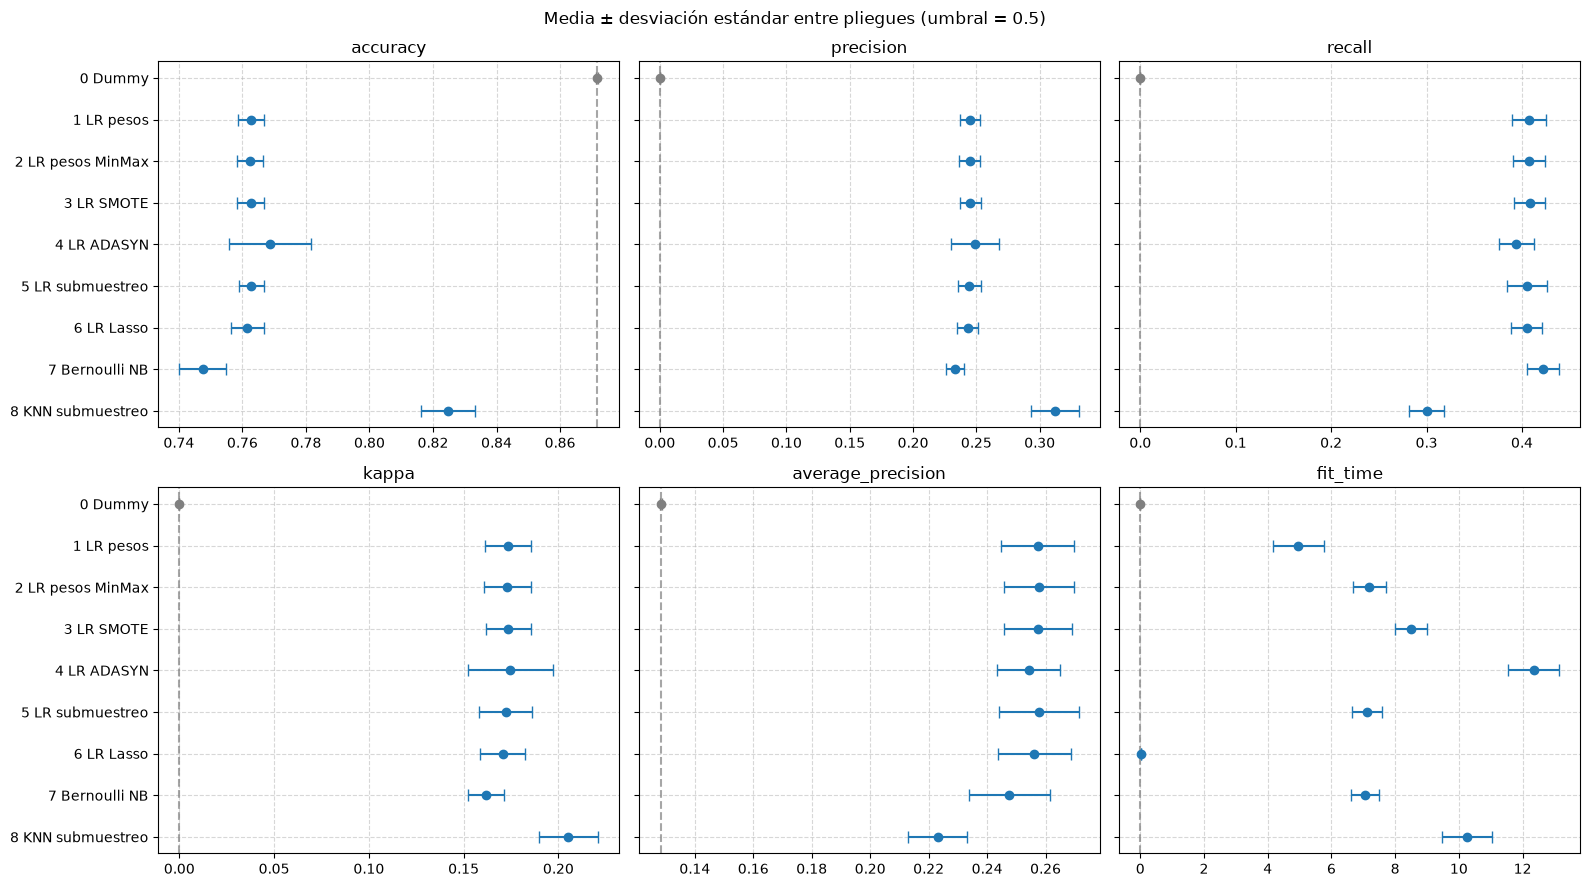

In [90]:
grafico_intervalos(
    resumen_std,
    "media",
    "std_inf",
    "std_sup",
    METRICAS,
    "Media ± desviación estándar entre pliegues "
    f"(umbral = {UMBRAL_COMPARACION})",
)
plt.show()

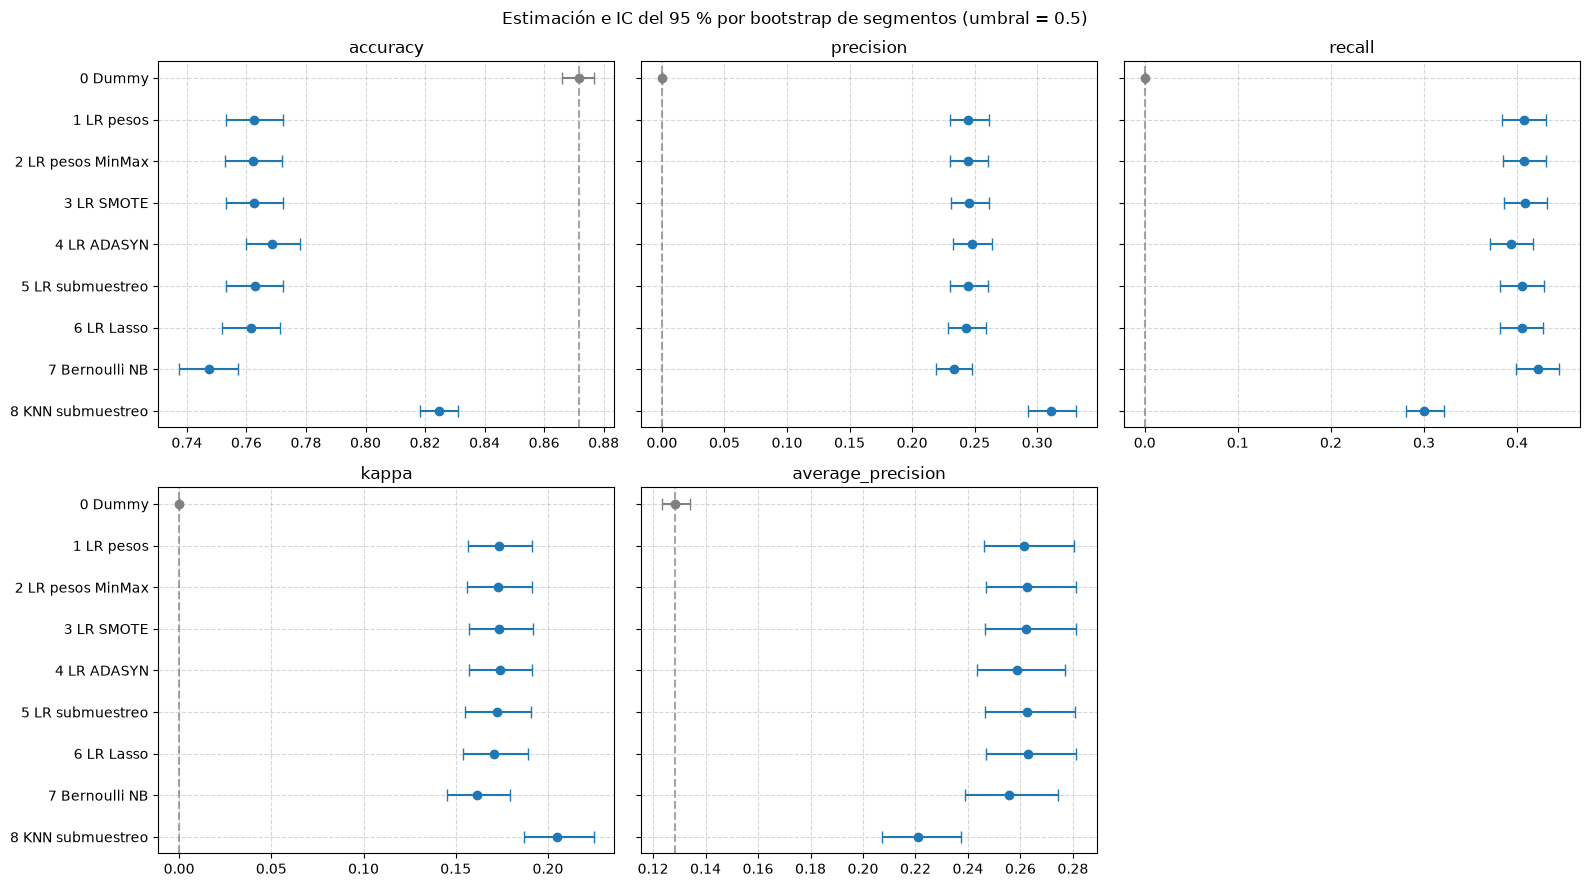

In [91]:
grafico_intervalos(
    resumen_ic,
    "estimacion",
    "ic_inf",
    "ic_sup",
    METRICAS_IC,
    "Estimación e IC del 95 % por bootstrap de segmentos "
    f"(umbral = {UMBRAL_COMPARACION})",
)
plt.show()

## Mosaicos

Las mismas gráficas de cada sección, lado a lado y con los mismos ejes (sin la línea base).

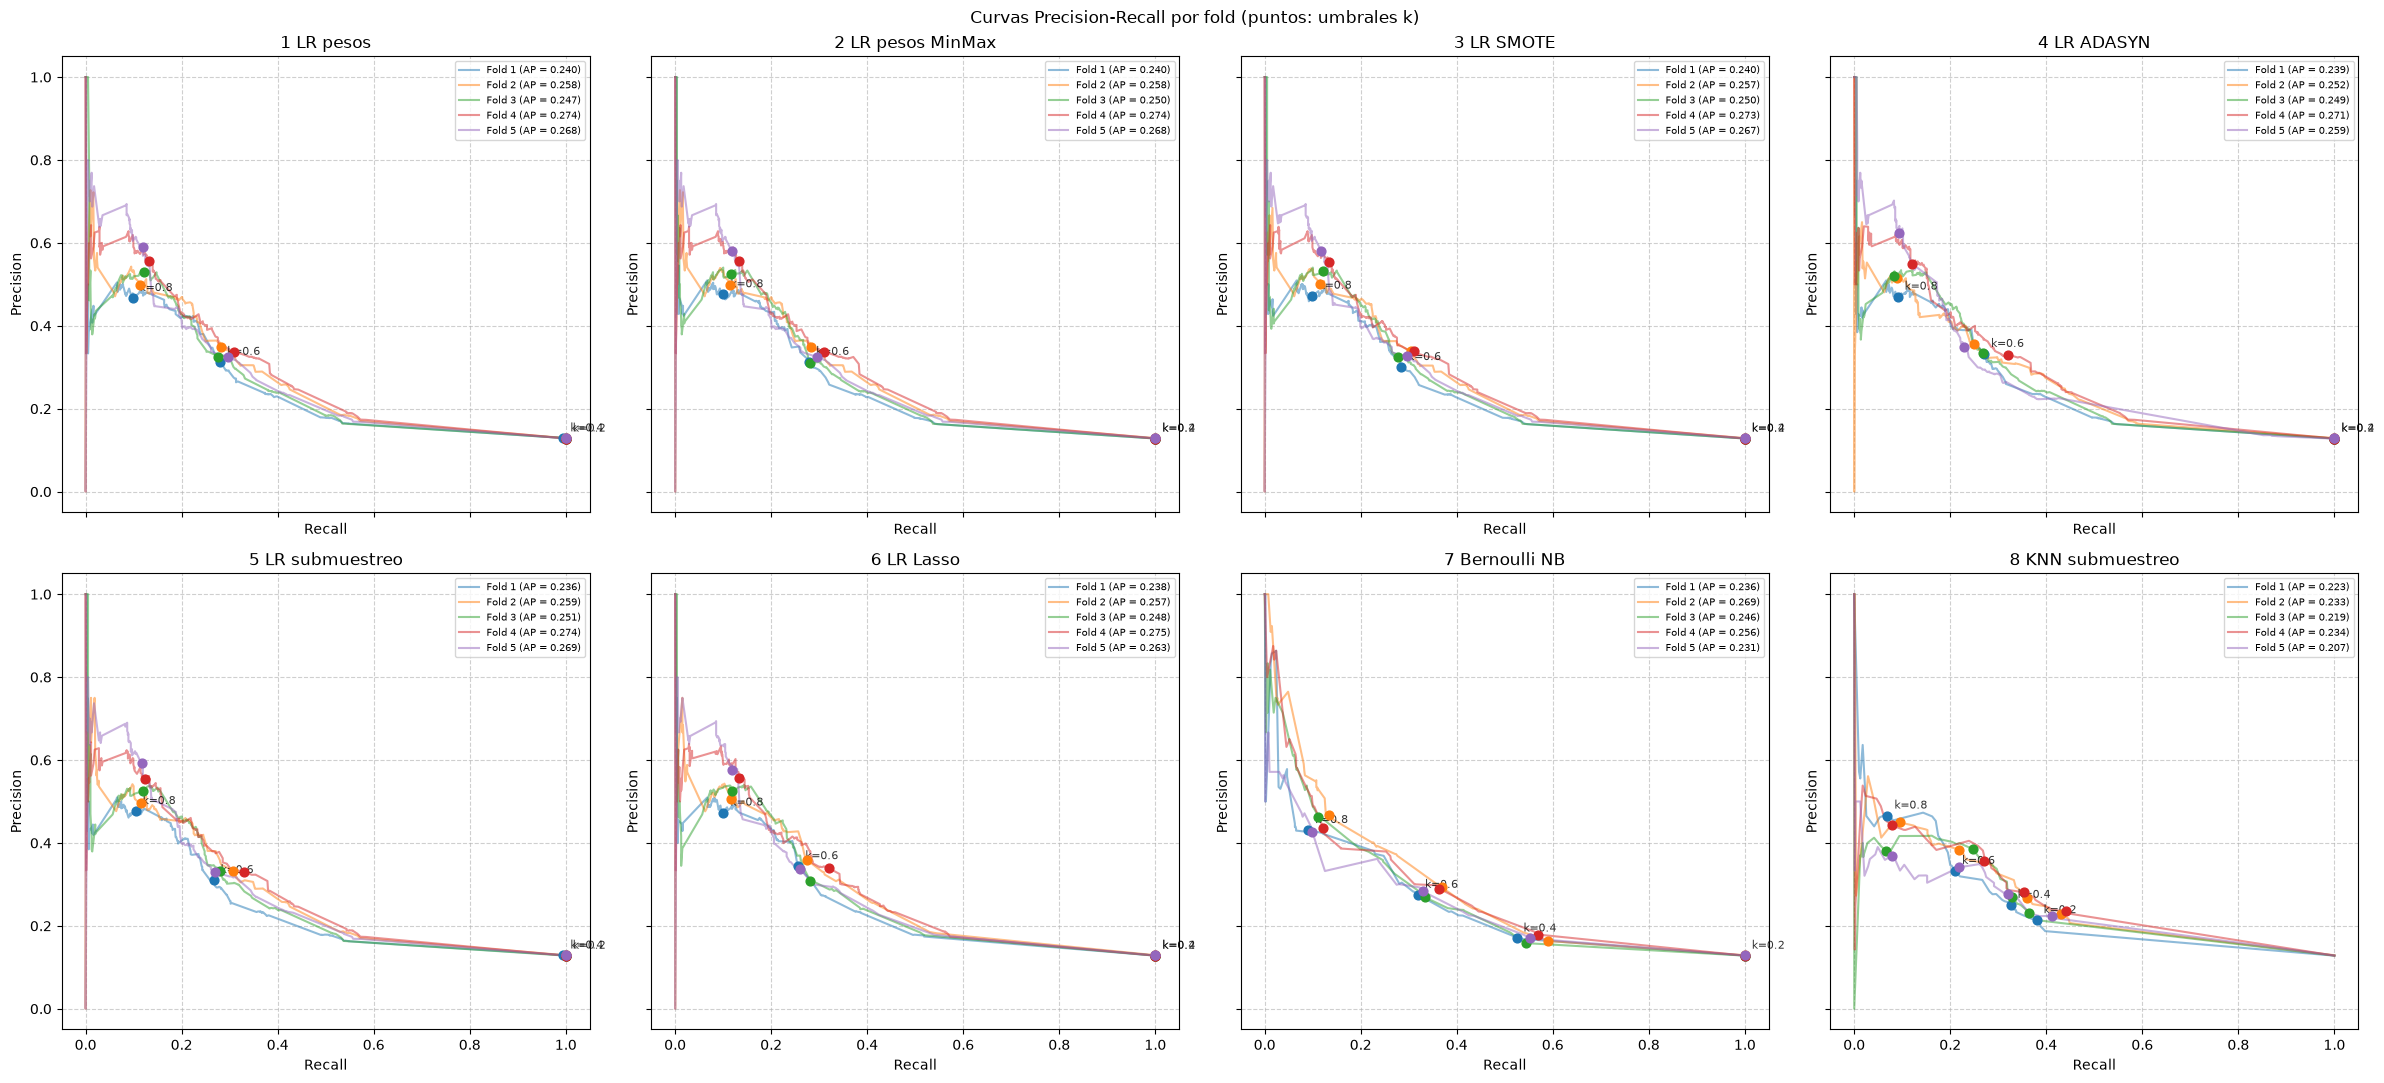

In [92]:
MODELOS_MOSAICO = {n: e for n, e in MODELOS.items() if n != NOMBRE_BASE}

fig, axes = plt.subplots(2, 4, figsize=(24, 11), sharex=True, sharey=True)
for ax, (nombre, ev_m) in zip(axes.flat, MODELOS_MOSAICO.items()):
    ev_m.curvas_pr(ax=ax)
    ax.set_title(nombre)
    ax.legend(loc="upper right", fontsize=7)
fig.suptitle("Curvas Precision-Recall por fold (puntos: umbrales k)")
fig.tight_layout()
plt.show()

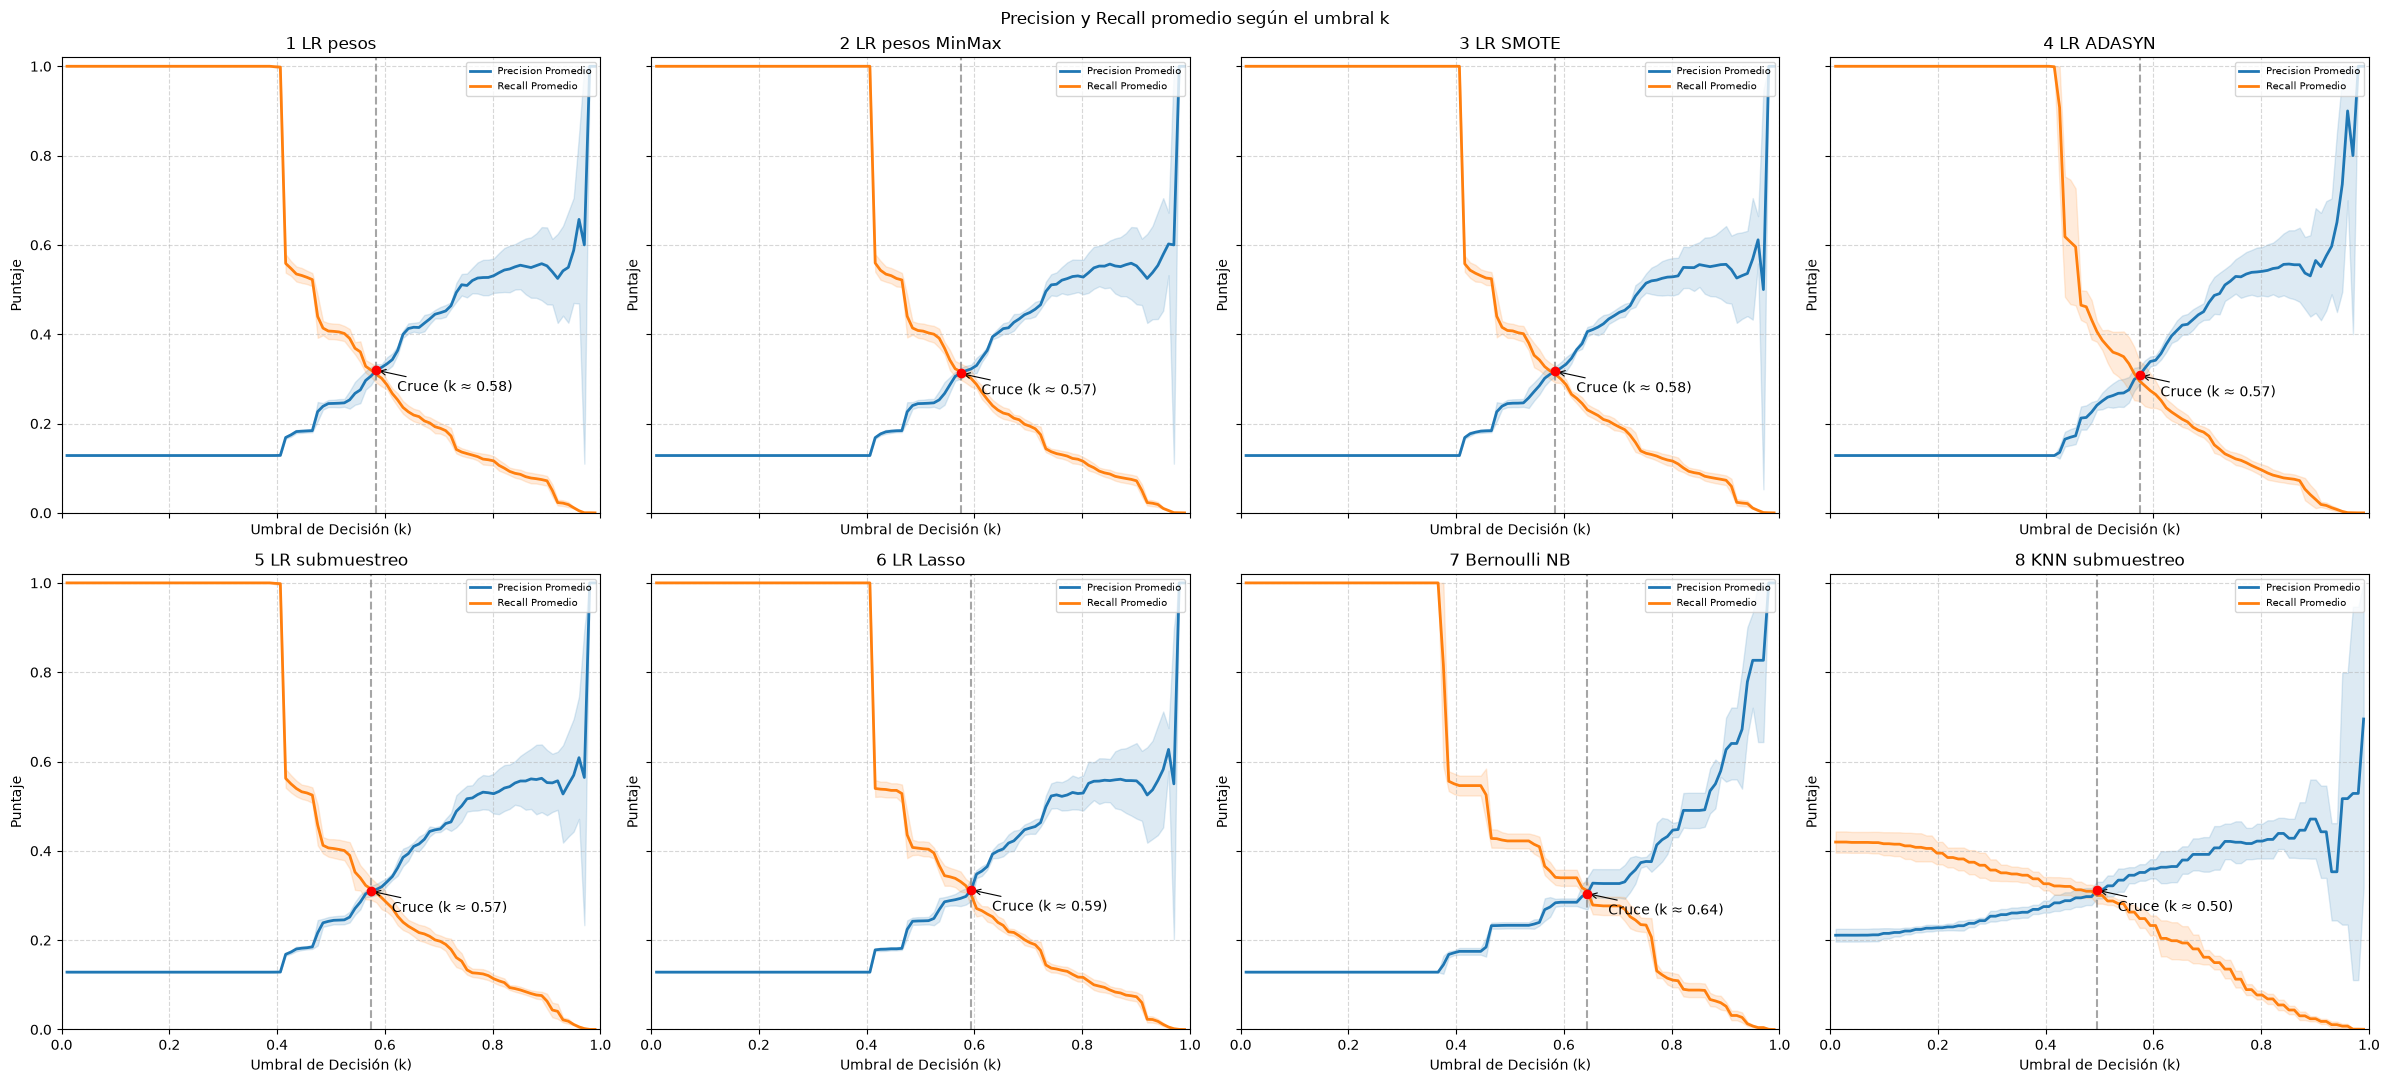

In [93]:
fig, axes = plt.subplots(2, 4, figsize=(24, 11), sharex=True, sharey=True)
for ax, (nombre, ev_m) in zip(axes.flat, MODELOS_MOSAICO.items()):
    ev_m.curva_umbral(ax=ax)
    ax.set_title(nombre)
    ax.legend(loc="upper right", fontsize=7)
fig.suptitle("Precision y Recall promedio según el umbral k")
fig.tight_layout()
plt.show()

## Variables y coeficientes

- **AOR** (solo regresiones logísticas): el AOR es por unidad de la escala con la que la variable entra al modelo, y esa escala cambia: el modelo 1 usa las variables sin escalar, los modelos 2 a 5 con MinMax (de 0 a 1) y el 6 estandarizadas (AOR por desviación estándar). Solo son comparables entre modelos con la misma escala; la etiqueta de cada modelo la indica. Las barras del gráfico van del AOR mínimo al máximo entre los 5 pliegues (no son intervalos de confianza); el punto es el AOR del coeficiente promedio.

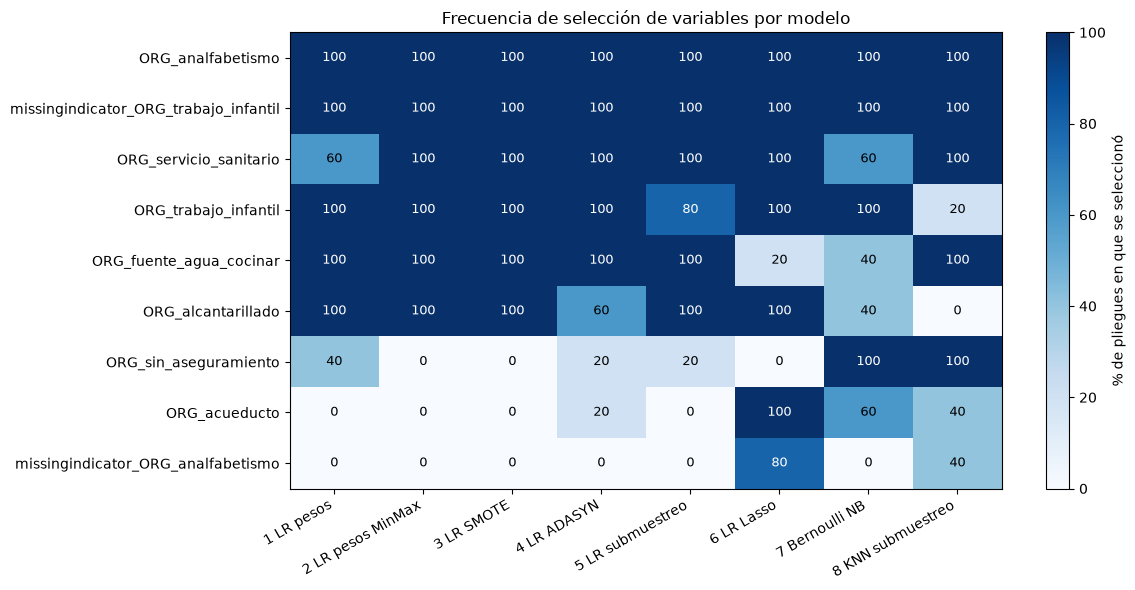

In [94]:
# % de pliegues en que se eligió cada variable (misma lógica que
# frecuencia_variables, sin imprimir)
seleccion = {}
for nombre, ev_m in MODELOS_MOSAICO.items():
    conteo = Counter()
    for estimador in ev_m.scores["estimator"]:
        nombres_imputed = estimador.named_steps[
            "imputer"
        ].get_feature_names_out(X_train.columns)
        mascara = estimador.named_steps["select_vars"].get_support()
        conteo.update(nombres_imputed[mascara])
    n_folds = len(ev_m.scores["estimator"])
    seleccion[nombre] = pd.Series(conteo) / n_folds * 100

df_seleccion = pd.DataFrame(seleccion).fillna(0)
orden = df_seleccion.mean(axis=1).sort_values(ascending=False).index
df_seleccion = df_seleccion.loc[orden]

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(df_seleccion, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(
    np.arange(df_seleccion.shape[1]),
    labels=df_seleccion.columns,
    rotation=30,
    ha="right",
)
ax.set_yticks(np.arange(df_seleccion.shape[0]), labels=df_seleccion.index)
for i in range(df_seleccion.shape[0]):
    for j in range(df_seleccion.shape[1]):
        valor = df_seleccion.iat[i, j]
        ax.text(
            j,
            i,
            f"{valor:.0f}",
            ha="center",
            va="center",
            color="white" if valor > 60 else "black",
            fontsize=9,
        )
fig.colorbar(im, ax=ax, label="% de pliegues en que se seleccionó")
ax.set_title("Frecuencia de selección de variables por modelo")
fig.tight_layout()
plt.show()

In [95]:
# Escala con la que entra cada variable: el AOR es por unidad de esa escala
ESCALA_AOR = {
    "1 LR pesos": "sin escalar",
    "2 LR pesos MinMax": "MinMax",
    "3 LR SMOTE": "MinMax",
    "4 LR ADASYN": "MinMax",
    "5 LR submuestreo": "MinMax",
    "6 LR Lasso": "estándar",
}
coefs_logit = {nombre: MODELOS[nombre].coeficientes() for nombre in ESCALA_AOR}
tabla_aor = pd.DataFrame(
    {
        f"{nombre} ({ESCALA_AOR[nombre]})": coefs["AOR"]
        for nombre, coefs in coefs_logit.items()
    }
)
tabla_aor.round(3)

,1 LR pesos (sin escalar),2 LR pesos MinMax (MinMax),3 LR SMOTE (MinMax),4 LR ADASYN (MinMax),5 LR submuestreo (MinMax),6 LR Lasso (estándar)
Característica,,,,,,
ORG_acueducto,NaN,NaN,NaN,1.379,NaN,1.068
ORG_alcantarillado,1.610,1.514,1.518,1.614,1.492,1.140
ORG_analfabetismo,14.538,14.520,14.923,10.316,15.463,1.510
ORG_fuente_agua_cocinar,1.026,1.229,1.240,1.137,1.275,1.008
ORG_servicio_sanitario,1.129,1.770,1.729,1.817,1.819,1.096
ORG_sin_aseguramiento,0.970,NaN,NaN,1.028,0.950,NaN
ORG_trabajo_infantil,2.739,2.728,2.688,2.354,2.638,1.094
missingindicator_ORG_analfabetismo,NaN,NaN,NaN,NaN,NaN,1.033
missingindicator_ORG_trabajo_infantil,0.773,0.775,0.770,0.892,0.773,0.901


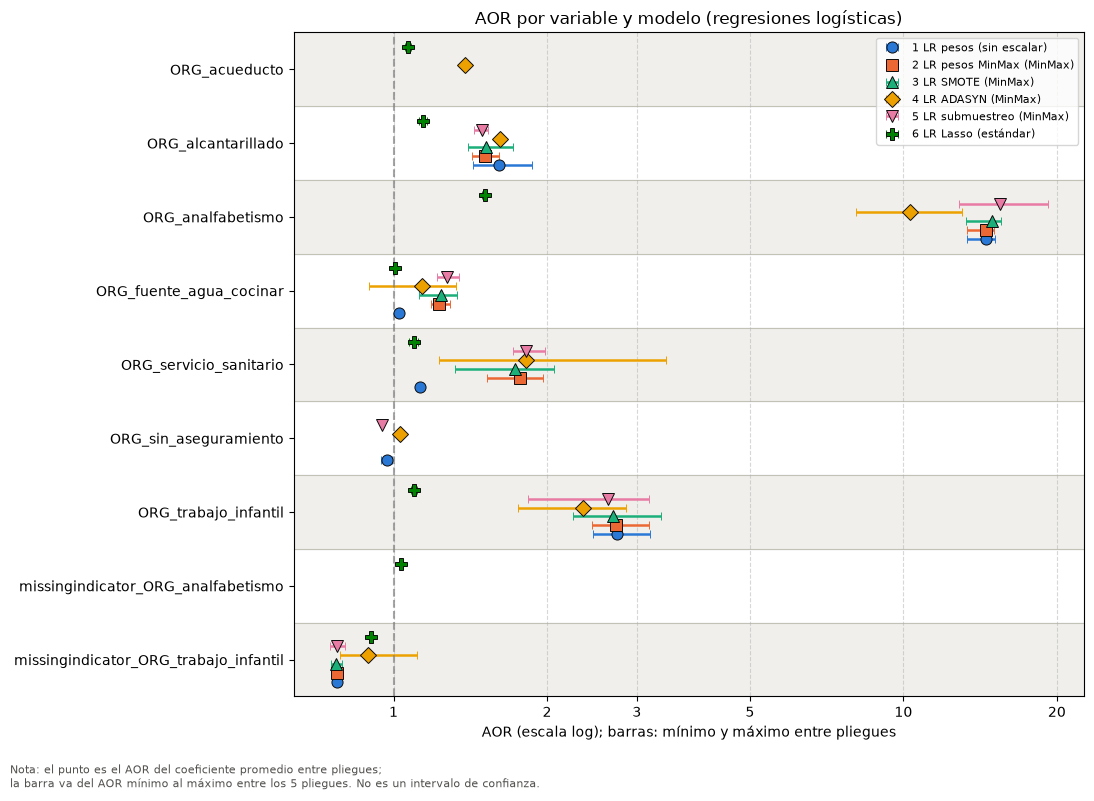

In [96]:
variables_aor = tabla_aor.index
y_base = np.arange(len(variables_aor))[::-1]
# Cada modelo un poco desplazado en vertical para que no se tapen
desplazamientos = np.linspace(-0.3, 0.3, len(coefs_logit))
# Paleta categórica de alto contraste en orden fijo, y un marcador
# distinto por modelo para no depender solo del color
PALETA_AOR = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
]
MARCADORES_AOR = ["o", "s", "^", "D", "v", "P"]


def grafico_aor(coefs_por_modelo, etiquetas, titulo, xlabel, nota):
    """Forest plot del AOR por variable y modelo, con franjas por variable.

    coefs_por_modelo : {modelo: DataFrame con AOR, AOR_Min y AOR_Max}
    etiquetas        : {modelo: texto de la leyenda}
    """
    fig, ax = plt.subplots(figsize=(11, 8))

    # Separación entre variables: franjas alternas y una línea entre filas
    for i, y in enumerate(y_base):
        if i % 2 == 0:
            ax.axhspan(y - 0.5, y + 0.5, color="#f0efec", zorder=0)
        if i > 0:
            ax.axhline(y + 0.5, color="#c3c2b7", lw=0.8, zorder=1)
    ax.set_ylim(-0.5, len(variables_aor) - 0.5)

    for (nombre, coefs), dy, color, marcador in zip(
        coefs_por_modelo.items(), desplazamientos, PALETA_AOR, MARCADORES_AOR
    ):
        datos = coefs.reindex(variables_aor)
        ax.errorbar(
            datos["AOR"],
            y_base + dy,
            xerr=[
                datos["AOR"] - datos["AOR_Min"],
                datos["AOR_Max"] - datos["AOR"],
            ],
            fmt=marcador,
            color=color,
            markersize=8,
            markeredgecolor="#0b0b0b",
            markeredgewidth=0.7,
            elinewidth=1.8,
            capsize=3,
            label=etiquetas[nombre],
        )
    ax.axvline(1, color="grey", linestyle="--", alpha=0.7)
    ax.set_xscale("log")
    # Marcas legibles en la escala log (sin notación científica)
    x_min, x_max = ax.get_xlim()
    # Rango amplio: marcas espaciadas; rango corto: marcas cerca de 1
    if x_max / x_min > 5:
        candidatas = (0.25, 0.5, 1, 2, 3, 5, 10, 20, 50)
    else:
        candidatas = (0.5, 0.75, 0.9, 1, 1.1, 1.25, 1.5, 2, 3)
    marcas = [m for m in candidatas if x_min <= m <= x_max]
    ax.set_xticks(marcas, labels=[f"{m:g}" for m in marcas])
    ax.minorticks_off()
    ax.set_yticks(y_base, labels=variables_aor)
    ax.set_xlabel(xlabel)
    ax.set_title(titulo)
    ax.legend(loc="best", fontsize=8)
    # Solo la rejilla vertical: las filas ya las separan las franjas
    ax.grid(True, axis="x", linestyle="--", alpha=0.5)
    # Aclaración: las barras no son intervalos de confianza
    fig.text(
        0.01, 0.005, nota, ha="left", va="bottom", fontsize=8, color="#52514e"
    )
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    return fig


grafico_aor(
    coefs_logit,
    {nombre: f"{nombre} ({ESCALA_AOR[nombre]})" for nombre in coefs_logit},
    "AOR por variable y modelo (regresiones logísticas)",
    "AOR (escala log); barras: mínimo y máximo entre pliegues",
    "Nota: el punto es el AOR del coeficiente promedio entre pliegues;\n"
    "la barra va del AOR mínimo al máximo entre los 5 pliegues. "
    "No es un intervalo de confianza.",
)
plt.show()

### AOR por desviación estándar

Para comparar los modelos en una misma escala, el AOR de cada uno se expresa por 1 desviación estándar (DE) de la variable, la misma unidad que usa la regresión Lasso con `StandardScaler`. No se reentrena: si una variable entra al modelo transformada linealmente, su coeficiente por 1 DE es el coeficiente ajustado por la DE de la variable tal como entra al modelo. La DE se calcula en las filas de entrenamiento de cada pliegue, antes del rebalanceo.

Es el mismo modelo ajustado expresado en otra unidad, así que los modelos 1 a 6 quedan comparables entre sí; el Lasso no cambia porque ya estaba en esa escala.

#### Cómo funciona la transformación

La regresión logística modela el log-odds como una combinación lineal de la variable tal como entra al modelo ($z$), es decir

$$\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta z$$

Todos los escalamientos usados son lineales, $z = a x + b$ donde $x$ es la variable original (sin escalar $a = 1$ y $b = 0$, con MinMax $a = \frac{1}{x_{max} - x_{min}}$), por lo tanto la desviación estándar de lo que entra al modelo es $s_z = a \, s_x$.

La versión estandarizada de la variable es $z^{*} = \frac{x - \bar{x}}{s_x}$, luego despejando $x = \bar{x} + s_x z^{*}$ y reemplazando en $z$ se tiene que

$$\beta z = \underbrace{\beta (a\bar{x} + b)}_{\text{va al intercepto}} + \underbrace{\beta \, s_z}_{\beta^{*}} \, z^{*}$$

Luego el coeficiente por una desviación estándar es simplemente $\beta^{*} = \beta \, s_z$ y el AOR estandarizado es

$$\text{AOR}^{*} = e^{\beta \, s_z} = \text{AOR}^{\,s_z}$$

Note que el modelo es exactamente el mismo, solo cambia la unidad en la que se lee el coeficiente; esto se hace en cada pliegue con la $s_z$ de su train y luego se resume igual que en `coeficientes()`. Para el Lasso $s_z = 1$, por eso su AOR no cambia.

Por ejemplo, en el modelo 1 ORG_analfabetismo tiene un $\text{AOR} \approx 14.54$ (pasar de 0 a 1 en la proporción) y en train su desviación estándar es $s_z \approx 0.153$, por lo tanto

$$\text{AOR}^{*} \approx 14.54^{0.153} \approx 1.50$$

es decir, aumentar en una desviación estándar (cerca de 15 puntos porcentuales) el analfabetismo del hogar multiplica los odds de pobreza por $1.5$, controlando por las demás variables del modelo.

In [97]:
# Coeficiente por 1 DE: coeficiente × DE de la variable tal como entra al
# modelo, en las filas de entrenamiento de cada pliegue
coefs_std = {}
for nombre in ESCALA_AOR:
    ev_m = MODELOS[nombre]
    registros = []
    for estimador, idx_tr in zip(
        ev_m.scores["estimator"], ev_m.scores["indices"]["train"]
    ):
        nombres_imputed = estimador.named_steps[
            "imputer"
        ].get_feature_names_out(X_train.columns)
        mascara = estimador.named_steps["select_vars"].get_support()
        # Entrada del modelo: los pasos previos ya ajustados, sin los
        # rebalanceos (solo actúan al entrenar y no tienen transform)
        x_modelo = X_train.iloc[idx_tr]
        for _, paso in estimador.steps[:-1]:
            if not hasattr(paso, "fit_resample"):
                x_modelo = paso.transform(x_modelo)
        de = np.std(x_modelo, axis=0)
        coefs = estimador.named_steps["model"].coef_[0]
        for var, coef, d in zip(nombres_imputed[mascara], coefs, de):
            registros.append({"Característica": var, "Coef_DE": coef * d})

    # Misma agregación que coeficientes(): exp de la media, mínimo y máximo
    por_variable = pd.DataFrame(registros).groupby("Característica")["Coef_DE"]
    coefs_std[nombre] = pd.DataFrame(
        {
            "AOR": np.exp(por_variable.mean()),
            "AOR_Min": np.exp(por_variable.min()),
            "AOR_Max": np.exp(por_variable.max()),
        }
    )

tabla_aor_std = pd.DataFrame(
    {nombre: coefs["AOR"] for nombre, coefs in coefs_std.items()}
).reindex(variables_aor)
tabla_aor_std.round(3)

,1 LR pesos,2 LR pesos MinMax,3 LR SMOTE,4 LR ADASYN,5 LR submuestreo,6 LR Lasso
Característica,,,,,,
ORG_acueducto,NaN,NaN,NaN,1.090,NaN,1.068
ORG_alcantarillado,1.188,1.161,1.163,1.189,1.155,1.140
ORG_analfabetismo,1.505,1.504,1.511,1.428,1.519,1.510
ORG_fuente_agua_cocinar,1.046,1.041,1.043,1.025,1.048,1.008
ORG_servicio_sanitario,1.099,1.093,1.089,1.098,1.097,1.096
ORG_sin_aseguramiento,0.996,NaN,NaN,1.004,0.993,NaN
ORG_trabajo_infantil,1.094,1.093,1.092,1.079,1.090,1.094
missingindicator_ORG_analfabetismo,NaN,NaN,NaN,NaN,NaN,1.033
missingindicator_ORG_trabajo_infantil,0.901,0.902,0.899,0.955,0.901,0.901


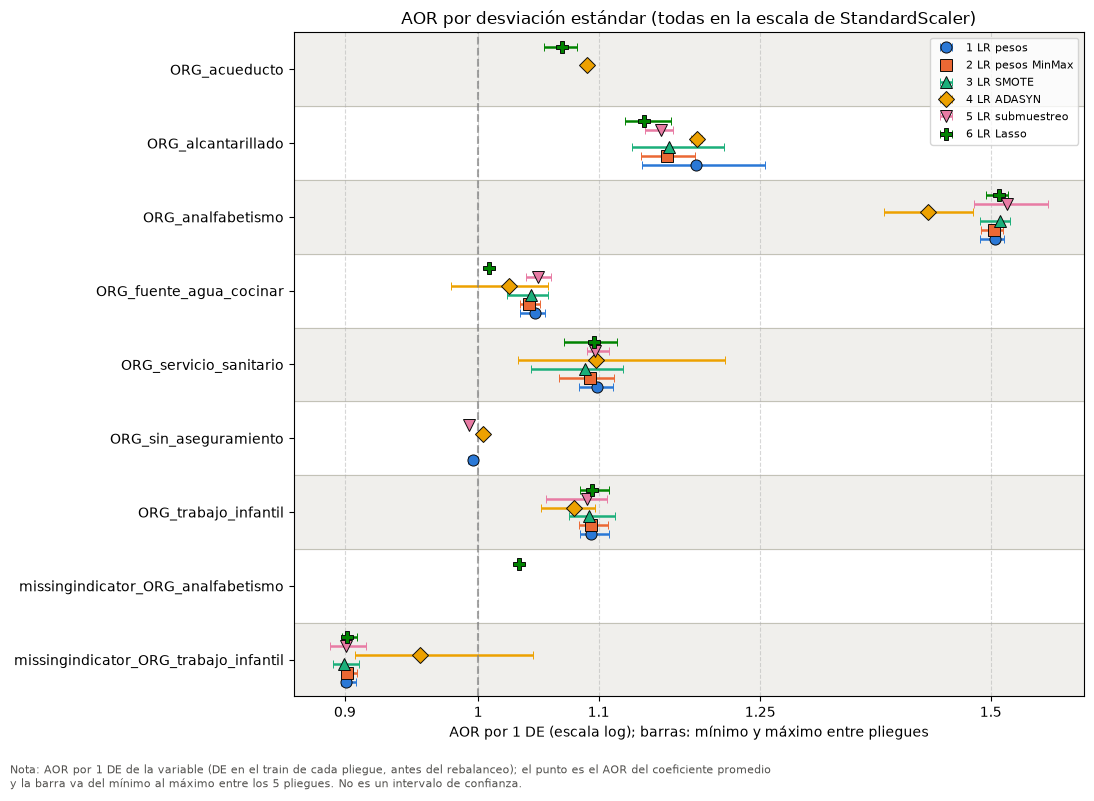

In [98]:
grafico_aor(
    coefs_std,
    {nombre: nombre for nombre in coefs_std},
    "AOR por desviación estándar (todas en la escala de StandardScaler)",
    "AOR por 1 DE (escala log); barras: mínimo y máximo entre pliegues",
    "Nota: AOR por 1 DE de la variable (DE en el train de cada pliegue, "
    "antes del rebalanceo); el punto es el AOR del coeficiente promedio\n"
    "y "
    "la barra va del mínimo al máximo entre los 5 pliegues. "
    "No es un intervalo de confianza.",
)
plt.show()

## Interpretar resultados

En primer lugar se descarta la opción de utilizar KNN pues a pesar de tener la precisión más alta es aquel que presento el peor recall, incluso cambiando el numero de vecinos o el umbral de decisión, asimismo se plantea descartar el naive bayes puesto que en general es peor que las regresiones logísticas y pierde interpretabilidad.

Bajo esto el rango de opciones baja a las diferentes regresiones logísticas evaluadas, sin embargo, estas son realmente similares entre sí y las variaciones entre las métricas de estas son potencialmente ruido, por esto el criterio de decisión pasa a ser la estabilidad del modelo, tanto en sus métricas como en sus coeficientes, y en este aspecto la ganadora es la regresión logística balanceada cuyo escalador es MinMax, dado que en general los coeficientes de las regresiones más estables son similares (aunque en la gráfica se ven diferencias grandes solo es por la escala), y lo mismo ocurre con las métricas el criterio que hace que esta sea la ganadora es la alta estabilidad en las características que selecciona y su simpleza en metodología del pipeline.

Esto hace que en esta iteración el **modelo ganador sea el correspondiente a la propuesta 2**.


> Nota: puesto que esta entrega no es la final no se evalúa con validation o test, eso se deja para la entrega final ya aplicando otros modelos como LDA, QDA y metodologias como `GridSearchCV`.

# Consideraciones del modelo ganador

Tomando el modelo 2 como el ganador se tiene que en la última sección este se comparo usando un umbral de 0.5, sin embargo se plantea que su umbral para las evaluaciones próximas sea cercano a 0.45 o 0.48 para tener un recall mejor a costa de una peor precisión, adicionalmente se adjunta la interpretación de sus coeficientes abajo.

In [99]:
ev_winner = EvaluadorCV(
    weighted_log_reg_2, X_train, y_train, 0.48, grupos_train, pickle=True
)

In [100]:
ev_winner.evaluar_cv()

umbral: 0.48
Resultados guardados en caché: /Users/juanpablocarrillo/Desktop/Externado/Cuarto_semestre/Machine_learning_1/Multidimesional_poverty_in_Colombia/data/cache_cv/f2a42db2da0c33ef5e9ba637442cf33b.pkl


In [101]:
ev_winner.resumen_metricas()

fit_time: 7.249 ± 0.379
score_time: 0.008 ± 0.000
test_accuracy: 0.754 ± 0.004
test_precision: 0.238 ± 0.007
test_recall: 0.416 ± 0.014
test_kappa: 0.167 ± 0.010
test_average_precision: 0.258 ± 0.012


<Axes: title={'center': 'Métricas promedio entre pliegues: train vs test'}, xlabel='Métrica', ylabel='Puntaje'>

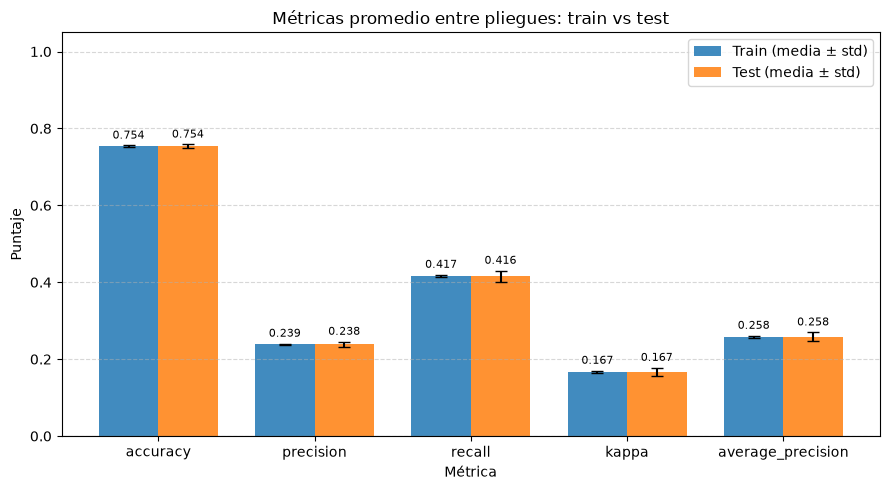

In [102]:
ev_winner.comparar_train_test()

<Axes: title={'center': 'Compromiso (Trade-off) Precision vs Recall según el Umbral k'}, xlabel='Umbral de Decisión (k)', ylabel='Puntaje'>

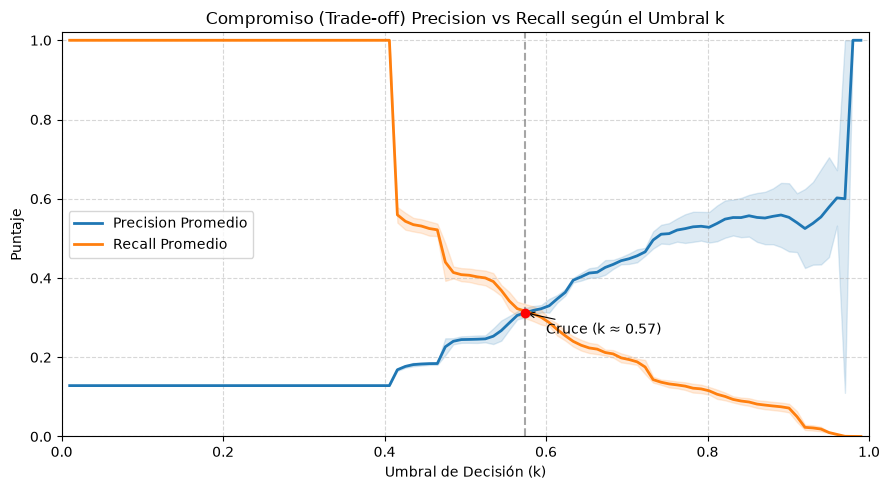

In [103]:
ev_winner.curva_umbral()

<Axes: title={'center': 'Curvas Precision-Recall por Fold con Puntos de Umbral (k)'}, xlabel='Recall', ylabel='Precision'>

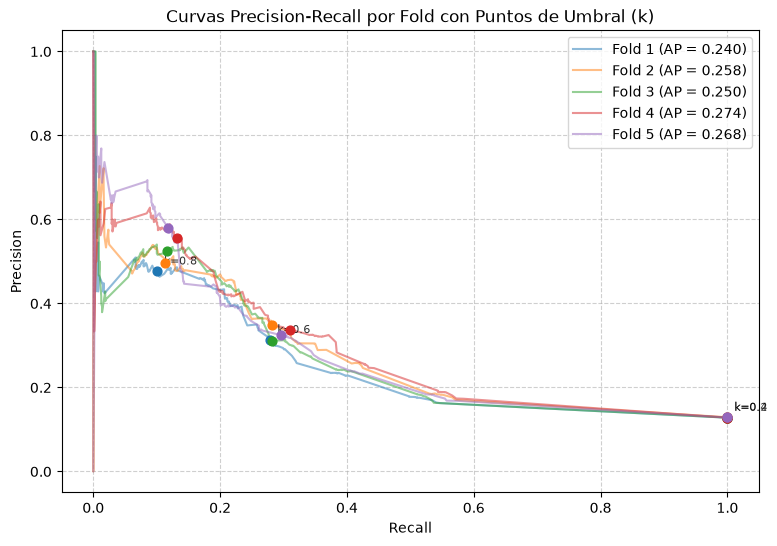

In [104]:
ev_winner.curvas_pr()

In [105]:
ev_winner.coeficientes()

,Coef_Promedio,Coef_Std,Veces_Seleccionada,Porcentaje,AOR,AOR_Min,AOR_Max
Característica,,,,,,,
ORG_alcantarillado,0.414485,0.046169,5,100.0,1.513591,1.428343,1.607440
ORG_analfabetismo,2.675554,0.050107,5,100.0,14.520399,13.349428,15.089316
ORG_fuente_agua_cocinar,0.206307,0.032507,5,100.0,1.229130,1.184615,1.290489
ORG_servicio_sanitario,0.570939,0.098138,5,100.0,1.769927,1.522920,1.966124
ORG_trabajo_infantil,1.003688,0.104150,5,100.0,2.728325,2.449820,3.173045
missingindicator_ORG_trabajo_infantil,-0.255254,0.012490,5,100.0,0.774720,0.765502,0.789940


In [106]:
# intepretacion con cambio del 0.1
DELTA = 0.1
coefs_winner = ev_winner.coeficientes()

# Rango original de cada variable (lo que MinMax lleva a 1), promedio entre
# pliegues: un cambio de 0.1 escalado equivale a 0.1 × rango original
rangos = []
for estimador in ev_winner.scores["estimator"]:
    nombres = estimador.named_steps["imputer"].get_feature_names_out(
        X_train.columns
    )[estimador.named_steps["select_vars"].get_support()]
    rangos.append(
        pd.Series(estimador.named_steps["scaler"].data_range_, index=nombres)
    )
rango_original = pd.concat(rangos, axis=1).mean(axis=1)

# Tipo de cada variable según sus valores en train, ya imputada
imputer_0 = ev_winner.scores["estimator"][0].named_steps["imputer"]
x_imputada = pd.DataFrame(
    imputer_0.transform(X_train),
    columns=imputer_0.get_feature_names_out(X_train.columns),
    index=X_train.index,
)


def tipo_variable(valores):
    if valores.nunique() == 2:
        return "binaria"
    if valores.between(0, 1).all() and (valores % 1 != 0).any():
        return "proporción"
    return "ordinal"


tipo = pd.Series(
    {var: tipo_variable(x_imputada[var]) for var in coefs_winner.index}
)
# Las binarias solo pasan de una categoría a la otra: se deja el AOR
# original (cambio completo); las demás se leen con un cambio de 0.1
delta = pd.Series(np.where(tipo == "binaria", 1.0, DELTA), index=tipo.index)

# OR para el cambio: AOR^delta (y su rango entre pliegues)
tabla_delta = pd.DataFrame(
    {
        "Tipo": tipo,
        "AOR": coefs_winner["AOR"],
        "Delta_escalado": delta,
        "OR_delta": coefs_winner["AOR"] ** delta,
        "OR_delta_Min": coefs_winner["AOR_Min"] ** delta,
        "OR_delta_Max": coefs_winner["AOR_Max"] ** delta,
    }
)
# Cambio porcentual de los odds de pobreza
tabla_delta["Cambio_odds_%"] = (tabla_delta["OR_delta"] - 1) * 100
tabla_delta["Delta_original"] = delta * rango_original
tabla_delta.sort_values("OR_delta", ascending=False).round(3)

,Tipo,AOR,Delta_escalado,OR_delta,OR_delta_Min,OR_delta_Max,Cambio_odds_%,Delta_original
ORG_alcantarillado,binaria,1.514,1.0,1.514,1.428,1.607,51.359,1.0
ORG_analfabetismo,proporción,14.520,0.1,1.307,1.296,1.312,30.677,0.1
ORG_trabajo_infantil,proporción,2.728,0.1,1.106,1.094,1.122,10.558,0.1
ORG_servicio_sanitario,ordinal,1.770,0.1,1.059,1.043,1.070,5.876,0.5
ORG_fuente_agua_cocinar,ordinal,1.229,0.1,1.021,1.017,1.026,2.084,0.9
missingindicator_ORG_trabajo_infantil,binaria,0.775,1.0,0.775,0.766,0.790,-22.528,1.0


$$\text{OR}_{\Delta=0.1} = e^{0.1 \times \ln(AOR)} \approx AOR^{0.1}$$

Las siguientes interpretaciones son todas considerando las demás variables constantes (controlando por).

- **ORG_analfabetismo:** Es el AOR más alto, esto sugiere que es la característica más determinante, luego un aumento de una unidad supondría que las odds son 14.5 veces más grandes, pero esto supondría un cambio de ningún analfabeta en el hogar a todos analfabetas, por lo tanto es más fácil interpretarlo como un cambio de 0.1, luego un aumento de 10 puntos porcentuales en la proporción de personas de 15 años o más analfabetas del hogar incrementaría los odds de pobreza en un $30.7\%$, es decir, por cada $10\%$ más de personas analfabetas del hogar los odds de ser pobre se multiplican por 1.307.

- **ORG_trabajo_infantil:** Es la proporción de personas de 12 a 17 años del hogar que trabajan, su AOR es 2.73, luego pasar de ningún menor trabajando a que todos trabajen multiplicaría los odds por 2.73, nuevamente es un cambio extremo, por lo tanto se interpreta como un cambio de 0.1, es decir, por cada 10 puntos porcentuales más de menores de 12 a 17 años que trabajan los odds de pobreza aumentan en un $10.6\%$ (se multiplican por 1.106). Note que en hogares con pocos menores el cambio es más brusco, por ejemplo si el hogar tiene un solo menor y este empieza a trabajar la proporción pasa de 0 a 1 y aplica el AOR completo.

- **ORG_alcantarillado:** Es una variable binaria (1 = tiene alcantarillado, 2 = no tiene), por lo tanto un cambio de 0.1 no tiene sentido y se usa el AOR completo, luego un hogar sin alcantarillado tiene unos odds de pobreza $51.4\%$ más altos que uno con alcantarillado, es decir, sus odds se multiplican por 1.514.

- **ORG_servicio_sanitario:** Es ordinal de 1 (inodoro conectado al alcantarillado) a 6 (sin servicio sanitario), como MinMax lleva ese rango de 5 categorías a 1, un cambio de 0.1 equivale a media categoría y supone un aumento de $5.9\%$ en los odds de pobreza, por lo tanto es más natural leerlo por una categoría completa, $1.770^{1/5} \approx 1.121$, es decir, cada categoría peor de servicio sanitario aumenta los odds de pobreza en un $12.1\%$, y pasar del mejor al peor servicio los multiplica por 1.77.

- **ORG_fuente_agua_cocinar:** Es ordinal de 1 (acueducto público) a 10 (agua embotellada o en bolsa), su rango es de 9 categorías, por lo tanto un cambio de 0.1 equivale a casi una categoría (0.9) y supone un aumento de $2.1\%$ en los odds de pobreza, por una categoría completa es $1.229^{1/9} \approx 1.023$, es decir, cada categoría peor de fuente de agua aumenta los odds de pobreza en un $2.3\%$ y pasar de la mejor a la peor los multiplica por 1.229, siendo la variable con menor efecto del modelo (también al expresarla por una desviación estándar).

- **missingindicator_ORG_trabajo_infantil:** Vale 1 cuando el hogar no tiene personas de 12 a 17 años, también es binaria, por lo tanto se usa el AOR completo, luego los hogares sin menores de esa edad tienen unos odds de pobreza $22.5\%$ más bajos (se multiplican por 0.775) que los hogares con menores en los que ninguno trabaja.

> Nota final: Este trabajo no reporta p-valores o intervalos de confianza matemáticos para los coeficientes de las regresiones logísticas, ya que la librería utilizada `scikit-learn` por defecto le aplica a la regresión logística una regularización L2, que sesga los coeficientes $\beta_j$ y subsecuentemente invalida las pruebas estadísticas mencionadas; adicionalmente, otro factor que invalida dichas pruebas estadísticas es el uso de `class_weight="balanced"` por razones similares a las anteriores. El pseudo $R^2$ solo se reporta como referencia en la primera propuesta y no es interpretable (de hecho es invalido) debido al uso de `class_weight="balanced"`.

> **Ojo:** Los intervalos de confianza que se reportan son para las métricas, estos se obtienen a partir de bootstrap; los 'intervalos' que ve en los gráficos de coeficientes no son más que el máximo y mínimo dentro de la validación cruzada.